# Data Scientist, Growth & MX Case Study
This test is meant to ensure you are comfortable performing the common tasks needed for this position. Please write detailed notes throughout your notebook as it will be reviewed by a member of the Facet team. You will also be interviewed about your results.

This is a modeling exercise. You should be able to take the dataset and data dictionary, and complete a classification model that displays reasonable accuracy.

In order to start, please ensure the following:
1. You have copied this notebook to your own area
2. You are connected to a runtime
3. The file "open_policing_project.parquet" has been placed into the current working directory and you are able to read it with read_parquet.


This should not take you more than 4 hours to complete.
Good luck!

In [ ]:
import pandas as pd

In [ ]:
import os
os.getcwd()

: 

In [ ]:
df = pd.read_parquet('open_policing_project.parquet')
df

,id,state,stop_date,stop_time,location_raw,county_name,county_fips,fine_grained_location,police_department,driver_gender,...,lon,aerial_enforcement,ethnicity,city,vehicle_year,vehicle_make,vehicle_model,vehicle_style,search_reason,stop_outcome_raw
0,NV-2012-00001,NV,2012-02-14,None,None,None,NaN,None,None,None,...,NaN,NaN,None,None,NaN,None,None,None,None,None
1,NV-2012-00002,NV,2012-02-14,None,None,None,NaN,None,None,None,...,NaN,NaN,None,None,NaN,None,None,None,None,None
2,NV-2012-00003,NV,2012-02-14,None,None,None,NaN,None,None,None,...,NaN,NaN,None,None,NaN,None,None,None,None,None
3,NV-2012-00004,NV,2012-02-14,None,None,None,NaN,None,None,None,...,NaN,NaN,None,None,NaN,None,None,None,None,None
4,NV-2012-00005,NV,2012-02-14,None,None,None,NaN,None,None,None,...,NaN,NaN,None,None,NaN,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
825113,MT-NA-07,MT,None,None,DAWSON,Dawson County,30021.0,CAINS COULEE ROAD X RADIO HILL ROAD,None,M,...,-104.734623,NaN,N,NOT IN CITY LIMITS,1998.0,PONTI,GRAND PRIX,SEDAN,None,WARNING
825114,MT-NA-08,MT,None,None,ROOSEVELT,Roosevelt County,30085.0,BIA ROUTE 1 WEST FORT KIPP 1 MILE,None,M,...,-104.785495,NaN,N,NOT IN CITY LIMITS,2011.0,DODGE,RAM 1500,PICKUP,None,WARNING
825115,MT-NA-09,MT,None,None,YELLOWSTONE,Yellowstone County,30111.0,STATE AVE. AND S. 27TH ST.,None,M,...,-108.492856,NaN,N,BILLINGS,1995.0,CHEVROLET (CHEV,C15,Pickup,None,"TRAFFIC CITATION,WARNING"
825116,MT-NA-10,MT,None,None,DAWSON,Dawson County,30021.0,MT 16 MM 10 SB,None,M,...,-104.646874,NaN,N,GLENDIVE,2004.0,DODGE (DODG),DURANGO,SPORT UTILITY,None,"MISDEMEANOR ARREST,WARNING"


## Modeling Exercise
Using the open policing data, you must produce the following. Your target is is_arrested.
1. An EDA of relationshps between the features of the dataset and the target variable
2. A binary classification model
3. Evaluation metrics of your model, including but not limited to:
  - Average Precision Score
  - F1 Score
  - ROC AUC

You should include markdown that appropriately explains the steps you're taking, and why.

# 1. Exploratory Data Analysis

**Goal:** understand how the features relate to each other and to `is_arrested`, with particular attention to the fact
that this table is really **five different state datasets stacked together** (MT, NV, RI, VT, WI). Each state's
agency recorded different fields, used different vocabularies, and has a different base arrest rate, so a pooled
view can be badly misleading (Simpson's paradox). Almost every relationship below is therefore shown **per state**.

Roadmap:
1. Setup & plotting helpers
2. Data coverage by state: which fields actually exist where
3. Data-quality audit: placeholder (constant-per-state) flags
4. The target across states and time
5. Target-leakage audit
6. Driver, time and violation features vs. arrest
7. Search / contraband / drug flags vs. arrest
8. Geography (county, department)
9. Feature engineering for the non-standardized free-text fields (`search_type_raw`/`search_type`, `stop_outcome`/`stop_outcome_raw`, `fine_grained_location`) plus vehicle age, followed by EDA of the new features
10. Feature-to-feature associations (Cramér's V) and per-state feature strength
11. Summary & implications for modeling

## 1.1 Setup & plotting helpers

All charts share one visual system so they can be compared at a glance:
* **Each state keeps one fixed color** in every chart (MT blue, NV orange, RI aqua, VT yellow, WI pink).
* **Arrest-rate heatmaps** use a single-hue blue scale (light = low, dark = high).
* **Lift heatmaps** show `rate in group ÷ state's overall rate` on a diverging blue ↔ red scale with a gray midpoint at 1.0×.
  Lift is the right lens here because base rates differ by state, so lift lets us ask whether a feature
  matters *within* a state.
* Groups with too few stops (`min_n`) are blanked rather than shown as noisy rates.

In [4]:
import re
import warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

# The parquet's stored index restarts at 0 for each state (2.3M duplicate labels), which breaks joins/alignment.
# There are no duplicate rows or ids, so a fresh RangeIndex is safe.
assert not df['id'].duplicated().any()
df = df.reset_index(drop=True)

# --- palette ------------------------------------------------------------------
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
STATES = sorted(df['state'].unique())
STATE_COLOR = dict(zip(STATES, SERIES))          # fixed: a state's color never changes between charts
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f0a3a2', '#b42f2f'])

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 9.5,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'text.color': INK, 'lines.linewidth': 2, 'legend.frameon': False,
    'axes.prop_cycle': mpl.cycler(color=SERIES),
})
PCT = mpl.ticker.PercentFormatter(1)

# --- helpers --------------------------------------------------------------------
def rate_table(data, col, by='state', min_n=300):
    # arrest rate of each `col` level within each `by` group, blanked where n < min_n
    g = data.groupby([col, by], observed=True)['is_arrested'].agg(['mean', 'size'])
    rate, n = g['mean'].unstack(by), g['size'].unstack(by)
    return rate.where(n >= min_n), n

def _heat(values, annot, ax, cmap, title, cbar_label, **kw):
    sns.heatmap(values, ax=ax, cmap=cmap, annot=annot, fmt='', annot_kws={'fontsize': 8},
                linewidths=2, linecolor=SURFACE, cbar_kws={'label': cbar_label, 'shrink': .8}, **kw)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(length=0); ax.grid(False)
    return ax

def rate_heatmap(rate, ax=None, title='', vmax=None):
    ax = ax or plt.subplots(figsize=(6, .35 * len(rate) + 1.2))[1]
    annot = rate.map(lambda v: '' if pd.isna(v) else f'{v:.1%}')
    return _heat(rate, annot, ax, SEQ, title, 'arrest rate', vmin=0, vmax=vmax)

STATE_BASE = df.groupby('state')['is_arrested'].mean()
def lift_heatmap(rate, ax=None, title='', lim=3):
    # lift = group rate / that state's overall arrest rate; colored on log2 scale so 2x and 0.5x are equidistant
    ax = ax or plt.subplots(figsize=(6, .35 * len(rate) + 1.2))[1]
    lift = rate / STATE_BASE[rate.columns]
    annot = lift.map(lambda v: '' if pd.isna(v) else f'{v:.1f}×')
    _heat(np.log2(lift), annot, ax, DIV, title, 'lift vs state base rate (log2)', center=0, vmin=-lim, vmax=lim)
    cb = ax.collections[0].colorbar
    cb.set_ticks(range(-lim, lim + 1)); cb.set_ticklabels([f'{2**t:g}×' for t in range(-lim, lim + 1)])
    return ax

def rate_lines(rate, ax=None, title='', xlabel=''):
    ax = ax or plt.subplots(figsize=(8, 3.6))[1]
    for s in rate.columns:
        ax.plot(rate.index, rate[s], color=STATE_COLOR[s], label=s)
    ax.yaxis.set_major_formatter(PCT); ax.set_ylim(bottom=0)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('arrest rate')
    ax.legend(title='state', loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8.5)
    return ax

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / n / (min(ct.shape) - 1))

## 1.2 Data coverage: what was actually recorded in each state

Before looking at relationships, it is essential to know **which fields exist in which state**. A column that is
100% missing in one state cannot carry signal there. Worse, its *missingness* becomes a proxy for state, and therefore
for that state's base arrest rate.

3,383,056 stops, 39 columns, 79,278 arrests (2.34%)


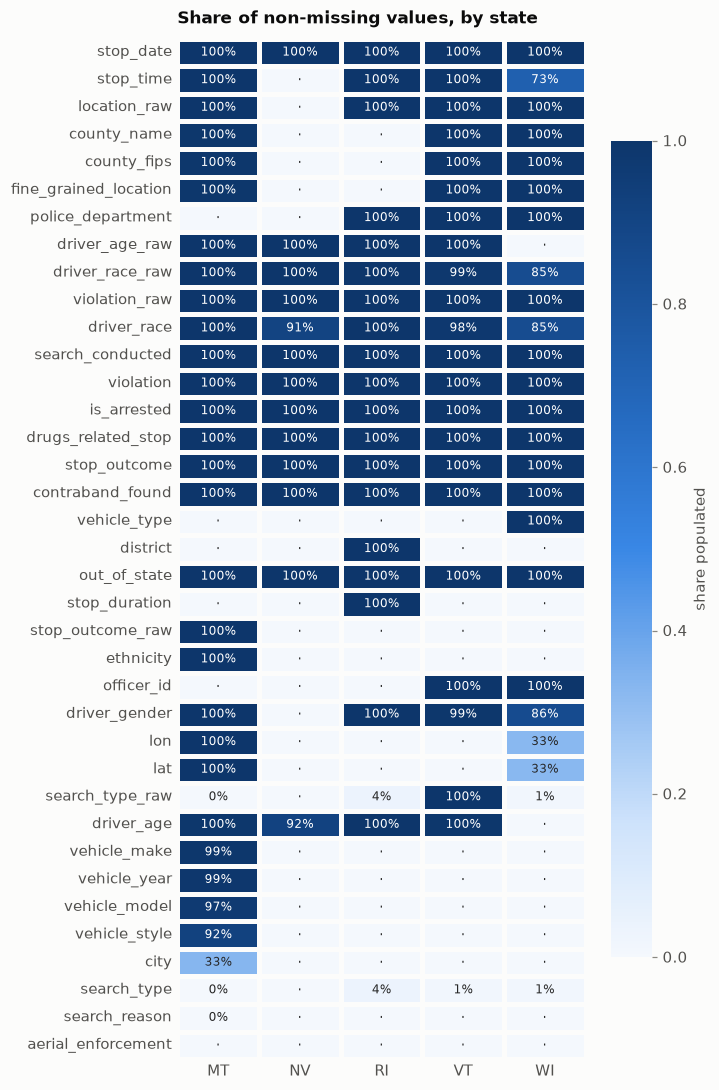

In [5]:
print(f'{len(df):,} stops, {df.shape[1]} columns, {df.is_arrested.sum():,} arrests ({df.is_arrested.mean():.2%})')

coverage = df.drop(columns=['id', 'state']).notna().groupby(df['state']).mean().T
coverage = coverage.loc[coverage.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 10))
_heat(coverage, coverage.map(lambda v: f'{v:.0%}' if v > 0 else '·'), ax, SEQ,
      'Share of non-missing values, by state', 'share populated', vmin=0, vmax=1)
plt.tight_layout(); plt.show()

**Observations**
* The five states are close to five different schemas. Only `stop_date`, `violation(_raw)`, the four boolean flags, `stop_outcome` and `is_arrested` are populated everywhere.
* **NV is the sparsest**: there is no time of day, no location of any kind, no gender, and no search details. Only age, race and violation describe an NV stop.
* **WI has no driver age** and is missing time of day on 27% of stops. **RI has no county**; its only geography is 6 patrol zones (`district`).
* `search_type`/`search_type_raw` exist for only a few percent of rows: VT's 100% is mostly the literal string "No Search Conducted". `aerial_enforcement` and `search_reason` are empty.
* MT-only fields (`ethnicity`, `city`, `vehicle_*`, `stop_outcome_raw`), RI-only fields (`stop_duration`, `district`) and the WI-only `vehicle_type` can only ever help within one state.

**Implication:** missingness is almost perfectly determined by state. A model can learn "this row has no `county_name`" = NV/RI = higher base rate, which is state identity rather than stop behavior. Any feature should be read as *state-conditional*.

## 1.3 Data-quality audit: boolean flags that are constant within a state

The boolean columns (`search_conducted`, `contraband_found`, `drugs_related_stop`, `out_of_state`) are never null, which
hides a problem: in some states they are **the same value for every single stop**. E.g. it is not plausible that 100% of
Nevada stops involved a search *and* found contraband. These are fill-in defaults, not observations, and must be treated
as *unknown* in those states.

In [6]:
BOOL_COLS = ['search_conducted', 'contraband_found', 'drugs_related_stop', 'out_of_state']
state_bool = df.groupby('state')[BOOL_COLS].mean()
placeholder = state_bool.isin([0.0, 1.0])     # value constant for every stop in that state

display(state_bool.style.format('{:.2%}').apply(
    lambda col: ['background-color:#f0a3a2' if placeholder.loc[s, col.name] else '' for s in col.index]))
print('Highlighted = constant across every stop in the state -> treated as not recorded.')

# Montana: contraband_found looks like a copy of search_conducted
mt = df.state.eq('MT')
print(f"MT rows where contraband_found == search_conducted: {(df.loc[mt, 'search_conducted'] == df.loc[mt, 'contraband_found']).mean():.2%}")

# Cleaned, nullable versions used for the rest of the EDA
for c in BOOL_COLS:
    df[c + '_clean'] = df[c].astype('boolean').mask(df['state'].map(placeholder[c]))

,search_conducted,contraband_found,drugs_related_stop,out_of_state
state,,,,
MT,0.37%,0.37%,100.00%,25.25%
NV,100.00%,100.00%,0.57%,100.00%
RI,3.70%,1.37%,0.99%,33.15%
VT,1.21%,0.97%,100.00%,100.00%
WI,15.68%,0.69%,0.51%,100.00%


Highlighted = constant across every stop in the state -> treated as not recorded.
MT rows where contraband_found == search_conducted: 100.00%


**Observations**
* **NV**: `search_conducted`, `contraband_found` and `out_of_state` are True for 100% of 737k stops. They are clearly fill-in defaults.
* **MT and VT**: `drugs_related_stop` is True for every stop. **VT and WI**: `out_of_state` is True for every stop.
* **MT**: `contraband_found` is an exact copy of `search_conducted` (100% agreement), so in MT it carries no information about contraband.
* These placeholder values have been set to missing in the `*_clean` columns. Used raw, they would make a model believe that, for example, *every* NV stop involved a search with contraband found, at an NV arrest rate of 3.6%. That would drag the learned effect of searching far down.

## 1.4 The target across states and over time

`is_arrested` is **highly imbalanced** (~2.3% positive) and the base rate differs about 3× between states. The data
also covers different time windows per state, so any time trend in the pooled data is partly a change in state mix.

,stops,arrests,arrest_rate,first,last,share_of_all_arrests
state,,,,,,
MT,"825,045","17,175",2.08%,2009-01-01,2016-12-31,21.7%
NV,"737,278","26,256",3.56%,2012-02-14,2016-05-31,33.1%
RI,"480,608","16,603",3.45%,2005-01-02,2015-12-31,20.9%
VT,"281,107","3,327",1.18%,2010-07-01,2015-12-31,4.2%
WI,"1,059,018","15,917",1.50%,2010-01-01,2016-05-16,20.1%


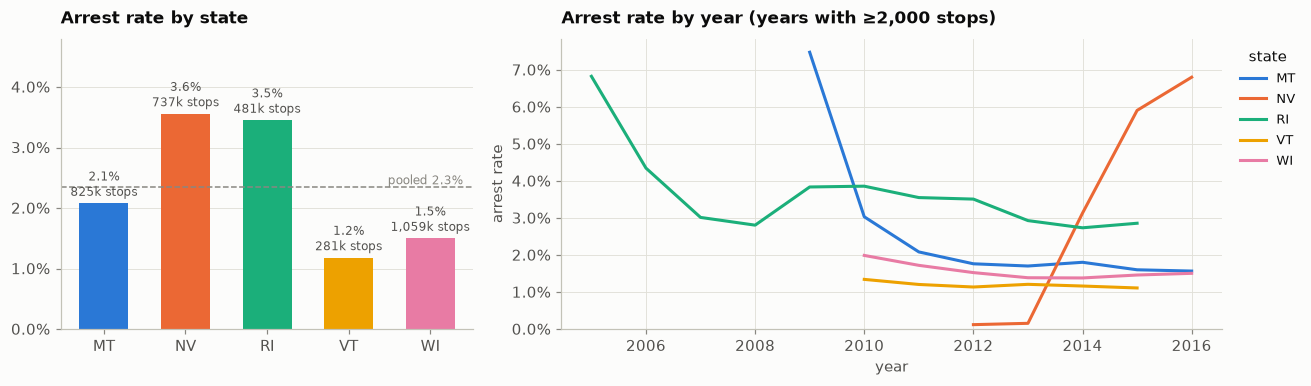

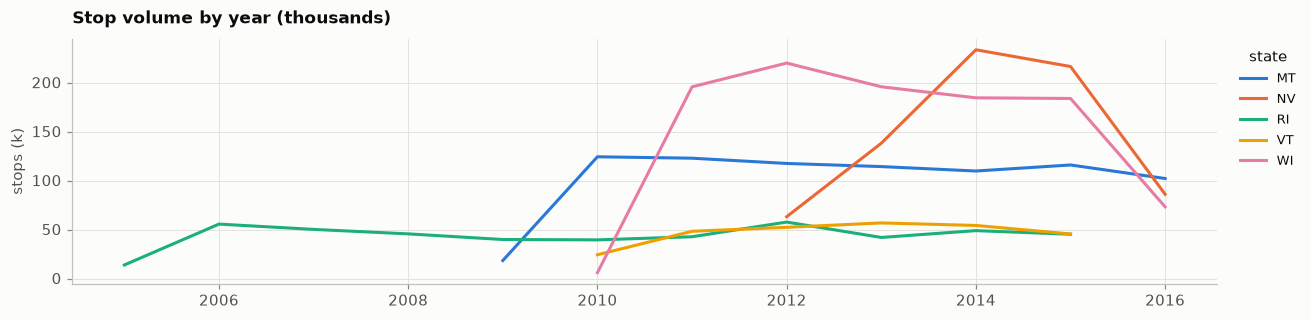

In [7]:
df['stop_date'] = pd.to_datetime(df['stop_date'])
df['year'] = df['stop_date'].dt.year

summary = df.groupby('state').agg(stops=('id', 'size'), arrests=('is_arrested', 'sum'),
                                  arrest_rate=('is_arrested', 'mean'),
                                  first=('stop_date', 'min'), last=('stop_date', 'max'))
summary['share_of_all_arrests'] = summary.arrests / summary.arrests.sum()
display(summary.style.format({'stops': '{:,}', 'arrests': '{:,}', 'arrest_rate': '{:.2%}',
                              'share_of_all_arrests': '{:.1%}', 'first': '{:%Y-%m-%d}', 'last': '{:%Y-%m-%d}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [1, 1.6]})
ax = axes[0]
bars = ax.bar(summary.index, summary.arrest_rate, color=[STATE_COLOR[s] for s in summary.index], width=.6)
ax.bar_label(bars, labels=[f'{r:.1%}\n{n/1e3:,.0f}k stops' for r, n in zip(summary.arrest_rate, summary.stops)],
             fontsize=8, color=INK2, padding=2)
ax.axhline(df.is_arrested.mean(), color=MUTED, lw=1, ls='--')
ax.annotate(f'pooled {df.is_arrested.mean():.1%}', (4.4, df.is_arrested.mean()), color=MUTED, fontsize=8, va='bottom', ha='right')
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, .048); ax.grid(axis='x', visible=False)
ax.set_title('Arrest rate by state')

yearly, yearly_n = rate_table(df.dropna(subset=['year']), 'year', min_n=2000)
rate_lines(yearly, axes[1], 'Arrest rate by year (years with ≥2,000 stops)', 'year')
axes[1].xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
for s in STATES:
    ax.plot(yearly_n.index, yearly_n[s] / 1e3, color=STATE_COLOR[s], label=s)
ax.set_title('Stop volume by year (thousands)'); ax.set_ylabel('stops (k)')
ax.legend(title='state', loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8.5)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

**Observations**
* The arrest rate ranges **3×** across states, from VT at 1.2% to NV at 3.6%. NV and RI together supply 54% of all arrests from only 36% of stops, so a pooled model's positives are dominated by those two states.
* The **time windows differ**: RI runs 2005–2015, MT 2009–2016, NV 2012–2016, VT and WI 2010–2016. The first and last years are partial for most states, and MT's partial 2009 (18k stops) has an unusually high 7.5% rate.
* MT, RI and WI show a gentle **downward drift** in arrest rate over time. NV shows a cliff-like **upward jump**, investigated next.

### Nevada: a change in how arrests were recorded

NV's yearly arrest rate climbs from ~0% to ~7%, which is far too steep to be real behavior. A quarterly view (below) shows a
step change in mid-2014, and a block of stops that all carry the same date.

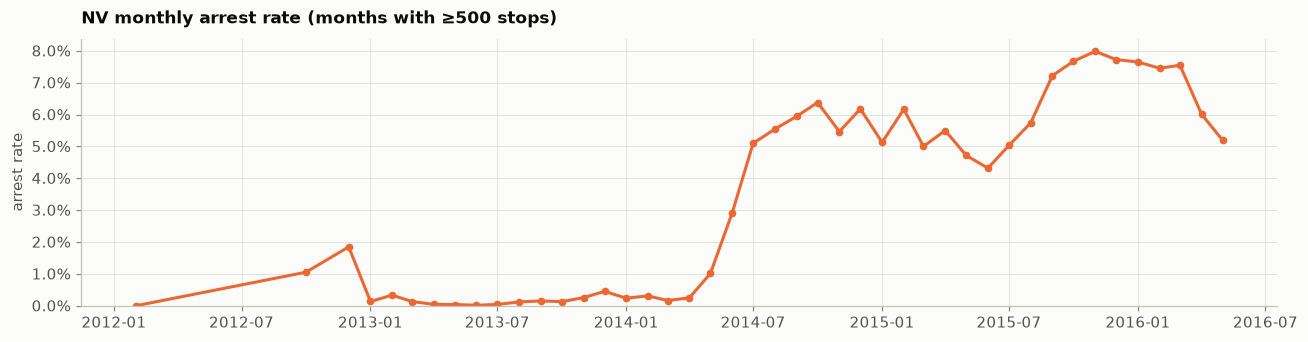

Most common NV stop_date: 2012-02-14 -> 59,570 stops (8.1% of NV), arrest rate 0.00%
Violation mix on that date: {'Other (non-mapped)': 0.666, 'Paperwork': 0.333, 'Safe movement': 0.001, 'Other': 0.0}
NV before 2014-07: 324,011 stops, arrest rate 0.39% | from 2014-07: 413,255 stops, arrest rate 6.05%


In [8]:
nv = df[df.state.eq('NV')]
nv_m = nv.groupby(nv.stop_date.dt.to_period('M'))['is_arrested'].agg(['mean', 'size'])
nv_m = nv_m[nv_m['size'] >= 500]

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(nv_m.index.to_timestamp(), nv_m['mean'], color=STATE_COLOR['NV'], marker='o', ms=4)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(bottom=0); ax.set_ylabel('arrest rate')
ax.set_title('NV monthly arrest rate (months with ≥500 stops)')
plt.tight_layout(); plt.show()

placeholder_date = nv.stop_date.value_counts().idxmax()
blk = nv[nv.stop_date.eq(placeholder_date)]
print(f'Most common NV stop_date: {placeholder_date:%Y-%m-%d} -> {len(blk):,} stops '
      f'({len(blk)/len(nv):.1%} of NV), arrest rate {blk.is_arrested.mean():.2%}')
print('Violation mix on that date:', blk.violation.value_counts(normalize=True).round(3).head(4).to_dict())

pre, post = nv[nv.stop_date < '2014-07-01'], nv[nv.stop_date >= '2014-07-01']
print(f'NV before 2014-07: {len(pre):,} stops, arrest rate {pre.is_arrested.mean():.2%} | '
      f'from 2014-07: {len(post):,} stops, arrest rate {post.is_arrested.mean():.2%}')

**Observations**
* NV's arrest rate is **0.39% before July 2014 and 6.05% after**, with the transition happening over about 2 months (May–July 2014). No real-world policing change produces a 15× step, so arrests were almost certainly **not being recorded** (or were recorded elsewhere) in the earlier extract.
* The single date **2012-02-14 holds 59,570 stops (8.1% of NV) with zero arrests**, and their violations are 67% "Other (non-mapped)" / 33% "Paperwork". This looks like a bulk back-load stamped with one date, not real daily activity.

**Implication:** about 324k NV rows (44% of NV) likely carry **false-negative labels**. Training on them teaches the model that NV stops before mid-2014 almost never end in arrest. Options: drop NV stops before 2014-07, or keep them with an indicator. Dropping is the cleaner choice for a model meant to generalize.

## 1.5 Target-leakage audit

Several columns are recorded **after** (or because of) the arrest. A model fed these would score near-perfect offline
and be useless in practice, so they have to be identified before any modeling. Checks:
* `stop_outcome` / `stop_outcome_raw` record what happened at the end of the stop.
* `search_type` "Incident to Arrest" (and usually "Inventory/Tow") are searches done *because* someone was arrested.
* `drugs_related_stop` and `contraband_found` are determined during or after a search, so they are post-stop information too.

In [9]:
leak = pd.crosstab([df.state, df.stop_outcome.fillna('(missing)')], df.is_arrested)
leak.columns = ['not arrested', 'arrested']
display(leak)

pure = (leak.min(axis=1) == 0).mean()
print(f'Share of (state, stop_outcome) combinations that map to a single is_arrested value: {pure:.0%}')

not arrested  arrested
state stop_outcome                                   
MT    Arrest                              0     17175
      Citation                       383686         0
      Faulty Equipment Notice          1316         0
      No Action                         197         0
      Warning                        422671         0
NV    Arrest                              0     26256
      Citation                       699530         0
      Warning                         11492         0
RI    Arrest Driver                       0     14630
      Arrest Passenger                    0      1973
      Citation                       428388         0
      N/D                              3431         0
      No Action                        3337         0
      Warning                         28849         0
VT    (missing)                         336         0
      Arrest for Violation                0      3251
      Citation                       106500         0
      Verbal Warning                     11         0
      Warrant Arrest                      0        76
      Written Warning                170933         0
WI    (missing)                         118         0
      Arrest                              0     15917
      Citation                       514093         0
      No Action                         941         0
      Verbal Warning                   2459         0
      Written Warning                525490         0

Share of (state, stop_outcome) combinations that map to a single is_arrested value: 100%


**Observations**
* Every `(state, stop_outcome)` combination maps to exactly one `is_arrested` value. `is_arrested` is literally derived from `stop_outcome` ("Arrest", "Arrest Driver", "Arrest Passenger", "Arrest for Violation", "Warrant Arrest").
* Note that RI's **"Arrest Passenger"** (1,973 stops) is counted as an arrest, so in RI the target includes stops where the driver was not arrested.

**Exclude from modeling:** `stop_outcome`, `stop_outcome_raw`, and anything derived from them. The search-type and `violation_raw` analyses below show further post-stop fields that need a deliberate decision.

## 1.6 Driver, time and violation features vs. arrest

### Driver demographics

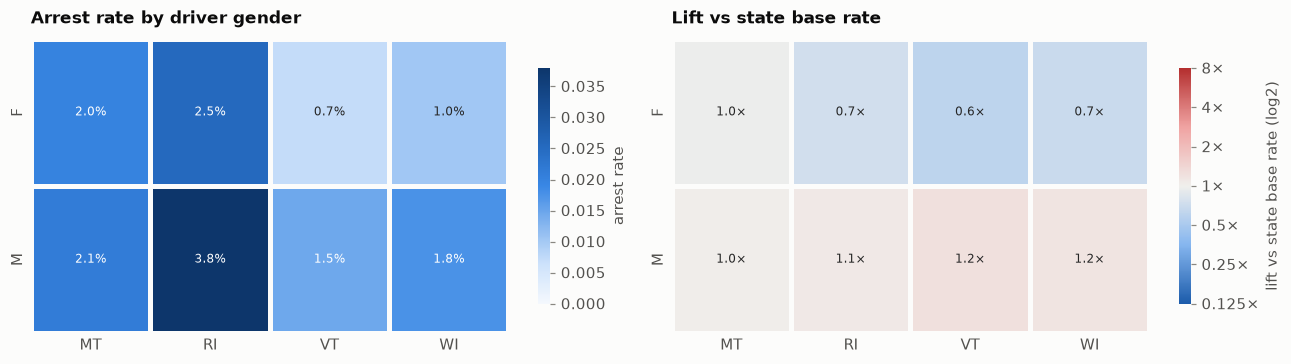

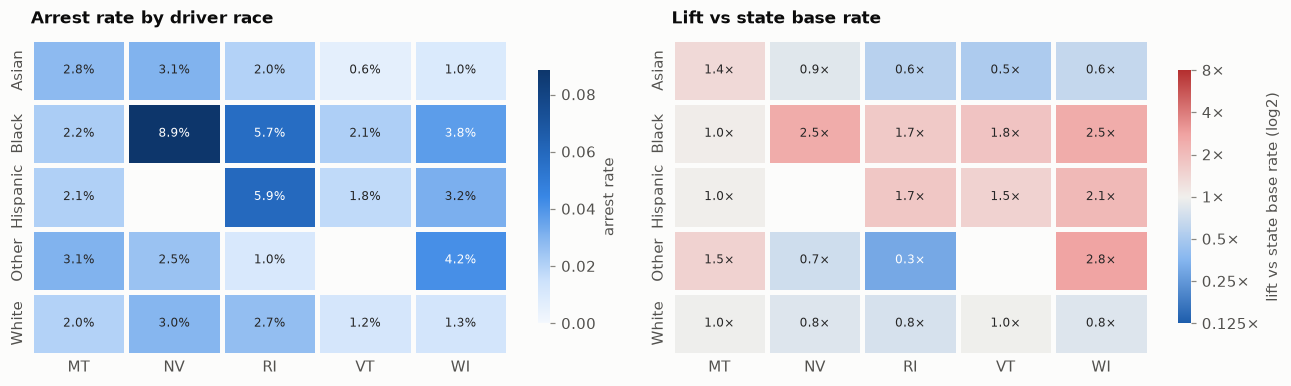

state,MT,NV,RI,VT,WI
race_missing,,,,,
False,2.08%,3.55%,3.45%,1.20%,1.51%
True,1.91%,3.66%,-,0.18%,1.45%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
g_rate, _ = rate_table(df, 'driver_gender')
rate_heatmap(g_rate, axes[0], 'Arrest rate by driver gender')
lift_heatmap(g_rate, axes[1], 'Lift vs state base rate')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
r_rate, r_n = rate_table(df, 'driver_race')
rate_heatmap(r_rate, axes[0], 'Arrest rate by driver race')
lift_heatmap(r_rate, axes[1], 'Lift vs state base rate')
plt.tight_layout(); plt.show()

# driver_race missingness itself, a frequent signal in policing data
miss = df.assign(race_missing=df.driver_race.isna()).pipe(rate_table, 'race_missing', min_n=100)[0]
display(miss.style.format('{:.2%}', na_rep='-').set_caption('Arrest rate when driver_race is missing (True) vs present'))

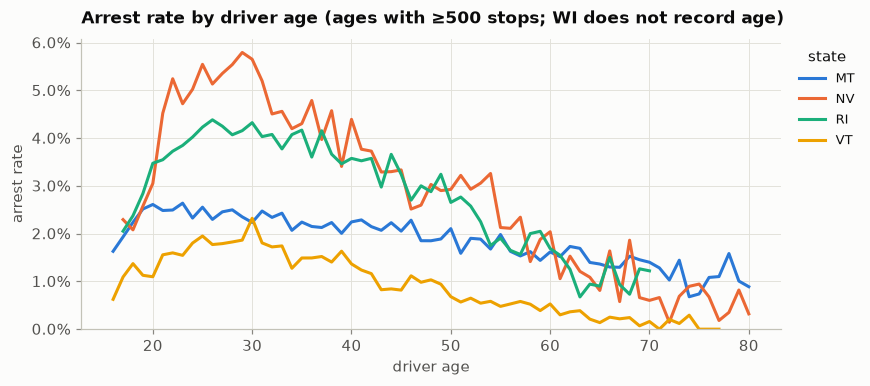

In [11]:
age = df[df.driver_age.between(16, 80)].assign(driver_age=lambda d: d.driver_age.round())   # one stray 22.5
a_rate, _ = rate_table(age, 'driver_age', min_n=500)
ax = rate_lines(a_rate, title='Arrest rate by driver age (ages with ≥500 stops; WI does not record age)', xlabel='driver age')
plt.tight_layout(); plt.show()

**Observations**
* **Gender**: male drivers are arrested at 1.1–1.2× their state's base rate and female drivers at 0.6–0.7×. MT is the exception, with no gender difference.
* **Race**: Black and Hispanic drivers are arrested at 1.5–2.5× the state base rate in NV, RI, VT and WI (NV Black drivers: 8.9% vs 3.0% for white drivers). MT shows no gap for Black or Hispanic drivers, but "Other" (which includes Native American drivers) is 1.5×. White and Asian drivers sit at or below base. Rates differ, but direction and size are state-specific.
* In VT, stops with **missing race** almost never end in arrest (0.18% vs 1.20%), a small recording artifact worth an indicator.
* **Age** is one of the clearer gradients. Arrest risk peaks in the mid-20s to early 30s (NV ~5.5%, RI ~4.4%) and declines steadily to under 1% by 70. MT is flatter (~2–2.5% until the mid-50s). WI has no age.

*Note:* race (and arguably gender) are protected attributes. They are predictive here, but whether they belong in a production arrest model is an ethical/legal decision, not just a statistical one. They should at least be audited for disparate impact in the modeling stage.

### Time of stop
Hour of day is parsed from `stop_time` (missing for all of NV and part of WI).

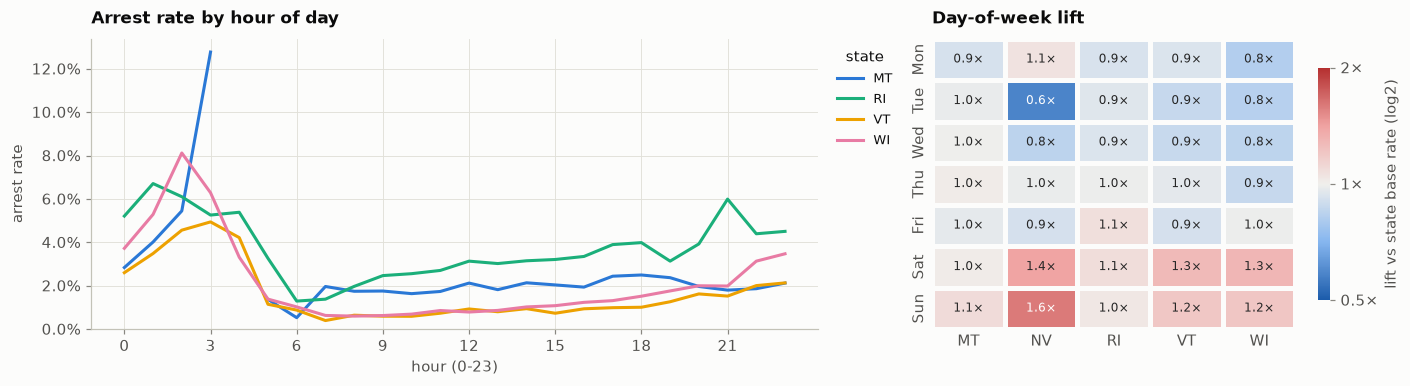

In [12]:
df['hour'] = pd.to_numeric(df['stop_time'].str[:2], errors='coerce')
df['day_of_week'] = df['stop_date'].dt.day_name().str[:3]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
h_rate, _ = rate_table(df, 'hour')
rate_lines(h_rate, axes[0], 'Arrest rate by hour of day', 'hour (0-23)')
axes[0].set_xticks(range(0, 24, 3))

dow_rate, _ = rate_table(df, 'day_of_week')
dow_rate = dow_rate.reindex(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
lift_heatmap(dow_rate, axes[1], 'Day-of-week lift', lim=1)
plt.tight_layout(); plt.show()

**Observations**
* **Hour of day has a strong, consistent shape**: arrests concentrate between midnight and 4am (WI ~8% at 2am, RI ~6–7%, MT spiking at 3am), bottom out around 6–8am (<1%), and rise slowly through the evening. Late-night stops are a different population (impaired driving, fewer routine speeding stops).
* **Weekends** run 1.2–1.6× the base rate (NV Sunday 1.6×, VT/WI Saturday 1.3×), mid-week slightly below. This is consistent with the overnight/DUI pattern.
* Hour and weekend should be engineered together, for example a `night` flag (22:00–04:00) or cyclical hour encoding, since 23:00 and 01:00 are neighbors.

### Violation (feature engineering: multi-label → indicator columns)

`violation` *is* standardized, but it is **multi-valued** in WI and MT (e.g. `"Paperwork,Speeding"`), giving 1,500+
distinct strings. Treating each string as a category would fragment the signal, so it is split into one indicator per
standardized violation plus a count of violations on the stop.

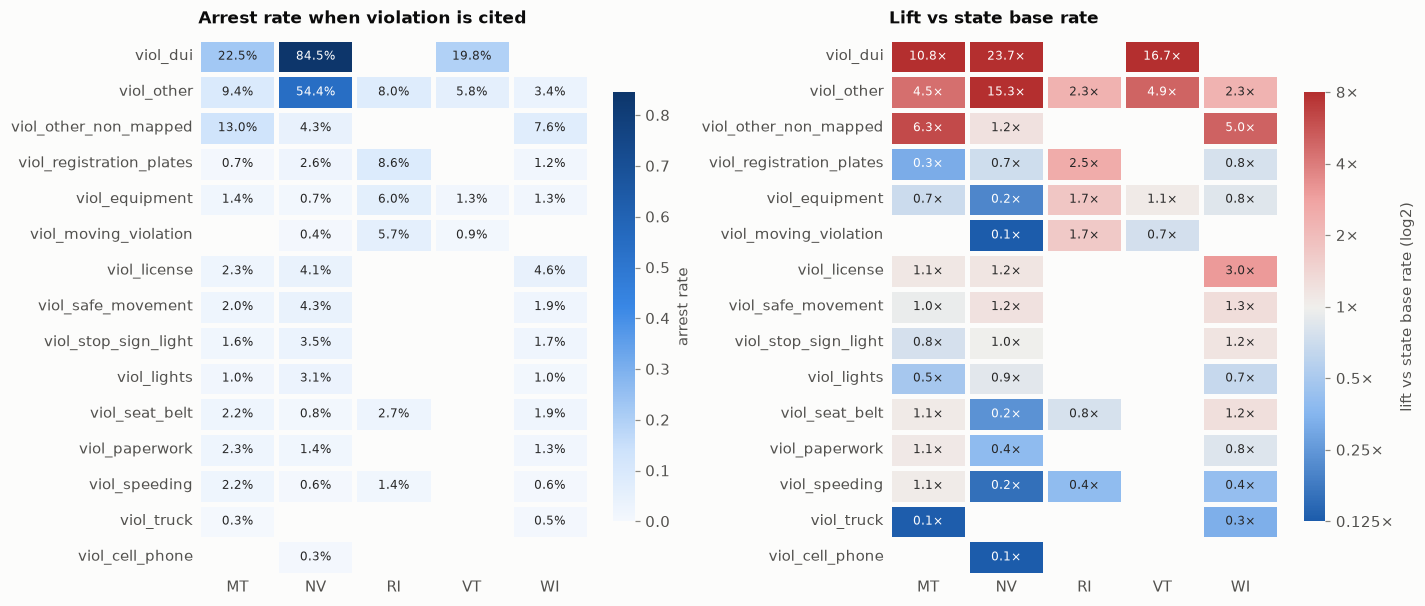

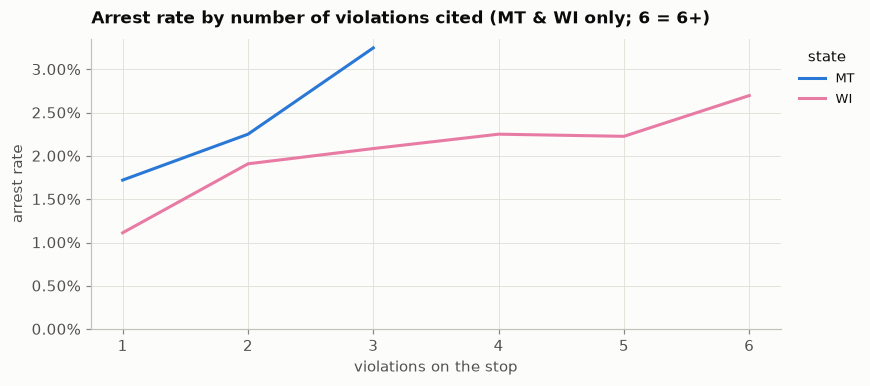

In [13]:
viol_dummies = df['violation'].str.get_dummies(sep=',').astype(bool)
viol_dummies.columns = ['viol_' + re.sub(r'\W+', '_', c.lower()).strip('_') for c in viol_dummies.columns]
df = df.join(viol_dummies)
df['n_violations'] = viol_dummies.sum(axis=1)
VIOL_COLS = list(viol_dummies.columns)

# arrest rate when each violation is present, per state
v_rate = pd.DataFrame({c: df[df[c]].groupby('state')['is_arrested'].agg(['mean', 'size'])
                       .pipe(lambda t: t['mean'].where(t['size'] >= 300)) for c in VIOL_COLS}).T
v_rate = v_rate.loc[v_rate.max(axis=1).sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
rate_heatmap(v_rate, axes[0], 'Arrest rate when violation is cited')
lift_heatmap(v_rate, axes[1], 'Lift vs state base rate')
plt.tight_layout(); plt.show()

nv_rate, _ = rate_table(df[df.state.isin(['MT', 'WI'])].assign(n_violations=df.n_violations.clip(upper=6)), 'n_violations')
rate_lines(nv_rate, title='Arrest rate by number of violations cited (MT & WI only; 6 = 6+)', xlabel='violations on the stop')
plt.tight_layout(); plt.show()

**Observations**
* **DUI** is by far the strongest standardized violation: 10.8× base in MT, 16.7× in VT and 23.7× in NV (84.5% of NV DUI stops end in arrest). DUI is effectively an arrestable offense by definition, so it sits close to the target.
* **"Other"/"Other (non-mapped)"** are the second strongest (2.3×–15×). That is surprising for a catch-all bucket, so it is examined below.
* Routine violations (**speeding, truck, cell phone, seat belt**) carry *below*-average risk (0.1–0.4× in NV/RI/WI). A pure speeding stop is a low-risk stop.
* The direction of some categories flips by state: registration/plates is 2.5× in RI but 0.3× in MT, and equipment is 1.7× in RI but 0.2× in NV. The same label means different things in different states' coding.
* **More violations means more arrests**: the rate rises steadily with the number of violations cited, in both MT and WI. `n_violations` is a simple, useful engineered feature.

### What hides inside "Other": keyword flags from `violation_raw`

The standardized `violation` lumps many charges into "Other" / "Other (non-mapped)", yet those buckets carry very high arrest rates
in NV and MT. The raw text shows why: they contain charges such as *"Fta Failure To Appear"* (a bench warrant) and
*"Possession Cocaine"*. These charges are **discovered during the stop** (warrant check, search), and some of them, like an
outstanding warrant, make an arrest close to automatic. They are extracted with keyword rules so they can be studied and
then deliberately included or excluded in modeling. VT (7 raw values) and RI (12 raw values) record only coarse categories,
so these flags exist mainly for NV, MT and WI.

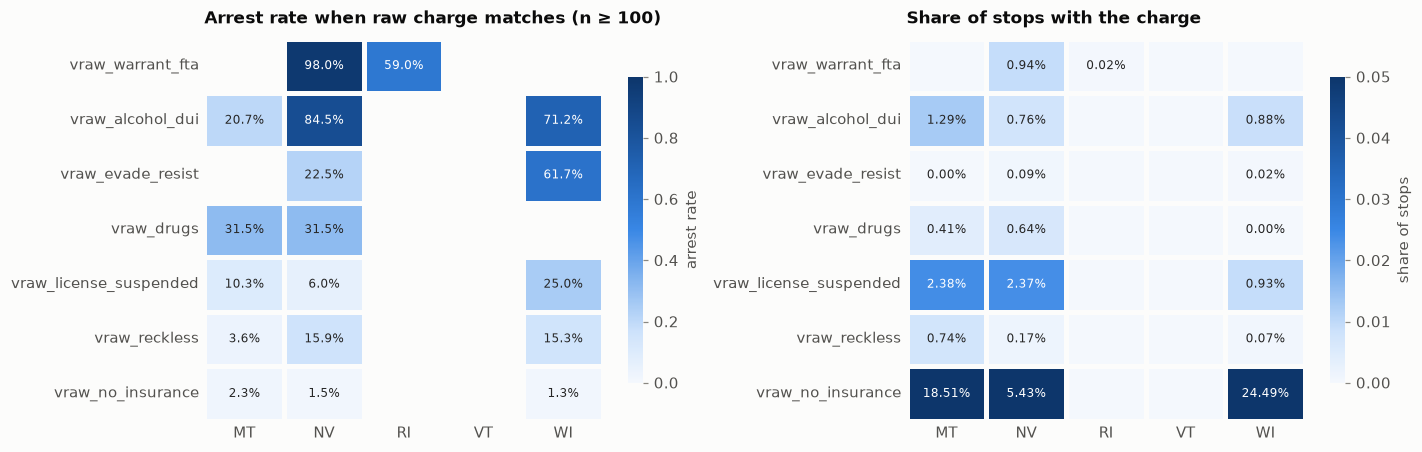

Share of all arrests whose stop carries a warrant / drug / alcohol charge:


,vraw_warrant_fta,vraw_drugs,vraw_alcohol_dui,any_of_three
state,,,,
MT,0.0%,6.2%,12.8%,18.0%
NV,25.7%,5.7%,18.0%,49.4%
RI,0.4%,0.0%,0.0%,0.4%
VT,0.0%,0.0%,0.0%,0.0%
WI,0.0%,0.1%,41.7%,41.8%


In [14]:
VRAW_FLAGS = {
    'warrant_fta':       r'\bFTA\b|FAILURE TO APPEAR|WARRANT',
    'drugs':             r'DRUG|COCAINE|MARIJUANA|NARCOTIC|CONTROLLED SUBSTANCE|PARAPHERNALIA|\bMETH|HEROIN|\bTHC\b',
    'alcohol_dui':       r'\bDUI\b|\bOWI\b|INTOXICA|UNDER THE INFLUENCE|ALCOHOL|LIQUOR|OPEN CONT|IMPLIED CONSENT|\bPAC\b|\bBAC\b',
    'license_suspended': r'SUSPEND|REVOK|\bOAR\b|\bOAS\b|CANCEL',
    'no_insurance':      r'INSURANCE',
    'evade_resist':      r'ELUD|\bFLEE|RESIST|OBSTRUCT(?:ING)? (?:AN )?OFFICER|FALSE (?:INFO|NAME)|DUTY TO GIVE',
    'weapon':            r'WEAPON|FIREARM|\bGUN\b|KNIFE',
    'theft_stolen':      r'THEFT|STOLEN',
    'reckless':          r'RECKLESS|CARELESS',
}
vraw = df['violation_raw'].str.upper()
for k, pat in VRAW_FLAGS.items():
    df['vraw_' + k] = vraw.str.contains(pat, regex=True).fillna(False).astype(bool)
VRAW_COLS = ['vraw_' + k for k in VRAW_FLAGS]

vr_rate = pd.DataFrame({c: df[df[c]].groupby('state')['is_arrested'].agg(['mean', 'size'])
                        .pipe(lambda t: t['mean'].where(t['size'] >= 100)) for c in VRAW_COLS}).T.reindex(columns=STATES)
vr_rate = vr_rate.dropna(how='all')     # weapon / theft never reach n >= 100 in any state
vr_rate = vr_rate.loc[vr_rate.max(axis=1).sort_values(ascending=False).index]
vr_share = df.groupby('state')[VRAW_COLS].mean().T.reindex(vr_rate.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rate_heatmap(vr_rate, axes[0], 'Arrest rate when raw charge matches (n ≥ 100)', vmax=1)
_heat(vr_share, vr_share.map(lambda v: f'{v:.2%}' if v > 0 else ''), axes[1], SEQ,
      'Share of stops with the charge', 'share of stops', vmin=0, vmax=.05)
plt.tight_layout(); plt.show()

print('Share of all arrests whose stop carries a warrant / drug / alcohol charge:')
arrests = df.loc[df.is_arrested, ['state', 'vraw_warrant_fta', 'vraw_drugs', 'vraw_alcohol_dui']]
arrests['any_of_three'] = arrests.iloc[:, 1:].any(axis=1)
display(arrests.groupby('state').mean().style.format('{:.1%}'))

**Observations**
* The keyword flags explain the "Other" bucket. **Failure-to-appear / warrant charges end in arrest 98% of the time in NV** and account for **25.7% of all NV arrests**. Alcohol charges account for 18% of NV arrests and **41.7% of WI arrests** (71% of WI alcohol-charge stops end in arrest). Drug charges run ~31% arrest in MT and NV.
* Together, warrant, drug and alcohol charges appear on **49% of NV arrests, 42% of WI arrests and 18% of MT arrests**.
* **Suspended/revoked license** is the main *routine* signal: 25% arrest rate in WI and 10% in MT, on 1–2% of stops.
* RI and VT only record coarse violation categories, so these flags are essentially absent there. This is another state asymmetry the model will feel.

**Implication (key modeling decision):** these charges are typically **recorded as a result of the stop**: a warrant hit after running the license, a failed sobriety test, drugs found during a search. If the model is meant to predict arrest from what is known when the stop begins, they leak and must be excluded, along with the standardized `viol_dui`/`viol_other` derived from them. If the model is meant to score a completed citation record, they are legitimate but will dominate. The EDA keeps them, flagged, so the trade-off is visible.

## 1.7 Search, contraband, drug and residency flags vs. arrest

Using the **cleaned** flags from §1.3 (placeholder states set to unknown). Each cell is the arrest-rate lift when the flag is
True, relative to that state's base rate.

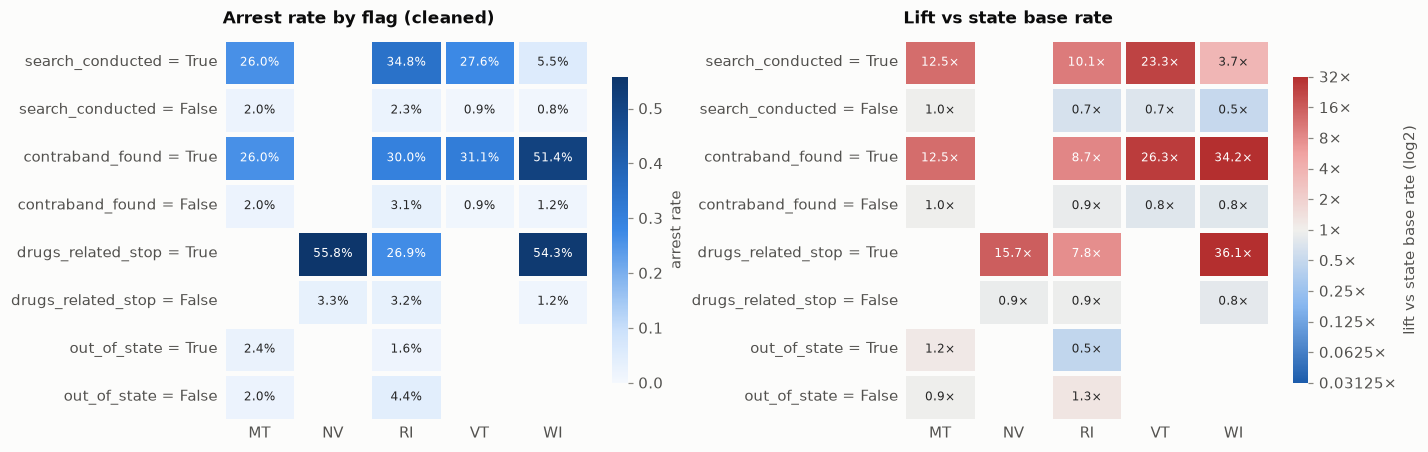

In [15]:
rows = {}
for c in BOOL_COLS:
    t = df.groupby(['state', c + '_clean'], observed=True)['is_arrested'].agg(['mean', 'size'])
    for val in [True, False]:
        if val in t.index.get_level_values(1):
            sub = t.xs(val, level=1)
            rows[f'{c} = {val}'] = sub['mean'].where(sub['size'] >= 300)
flag_rate = pd.DataFrame(rows).T.reindex(columns=STATES)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rate_heatmap(flag_rate, axes[0], 'Arrest rate by flag (cleaned)')
lift_heatmap(flag_rate, axes[1], 'Lift vs state base rate', lim=5)
plt.tight_layout(); plt.show()

# How common is each flag, and what share of arrests involved it?
prev = df.groupby('state')[[c + '_clean' for c in BOOL_COLS]].mean()
prev_arrest = df[df.is_arrested].groupby('state')[[c + '_clean' for c in BOOL_COLS]].mean()
display(pd.concat({'share of stops': prev, 'share of arrests': prev_arrest}, axis=1)
        .style.format('{:.1%}', na_rep='n/a'))

**Observations** (with placeholder states removed)
* **Searches are the strongest behavioral signal**: a searched stop is arrested 26% (MT), 35% (RI) or 28% (VT) of the time, 10–23× the base rate. 37% of RI arrests and 28% of VT arrests involved a search.
* **WI is different**: 15.7% of WI stops are flagged as searched (vs 0.4–3.7% elsewhere), but only 5.5% of those end in arrest (3.7×). WI's `search_conducted` evidently captures something broader than the other states' flag, and only 9% of WI's "searches" have a recorded basis (§1.9.1). The same column has a different meaning in WI.
* **Contraband found** and **drug-related stop** push arrest rates to 27–56%, most extremely in WI (contraband 51% → 34× base; drug-related 54% → 36×).
* **Out-of-state drivers** are *less* likely to be arrested in RI (0.5×) and slightly more in MT (1.2×). This is only measurable in those two states.

**Implication:** search, contraband and drug-related are all determined *during* the stop, often in the same chain of events as the arrest (search incident to arrest, drugs found → arrest). As with the raw charge flags, include them only if the use case scores stops after they have unfolded.

## 1.8 Geography: how much does arrest rate vary *within* a state?

If counties or departments within a state differ a lot, location is worth encoding (e.g. target encoding). Each dot is
one county (or department/district for RI, which has no county), restricted to units with ≥500 stops.

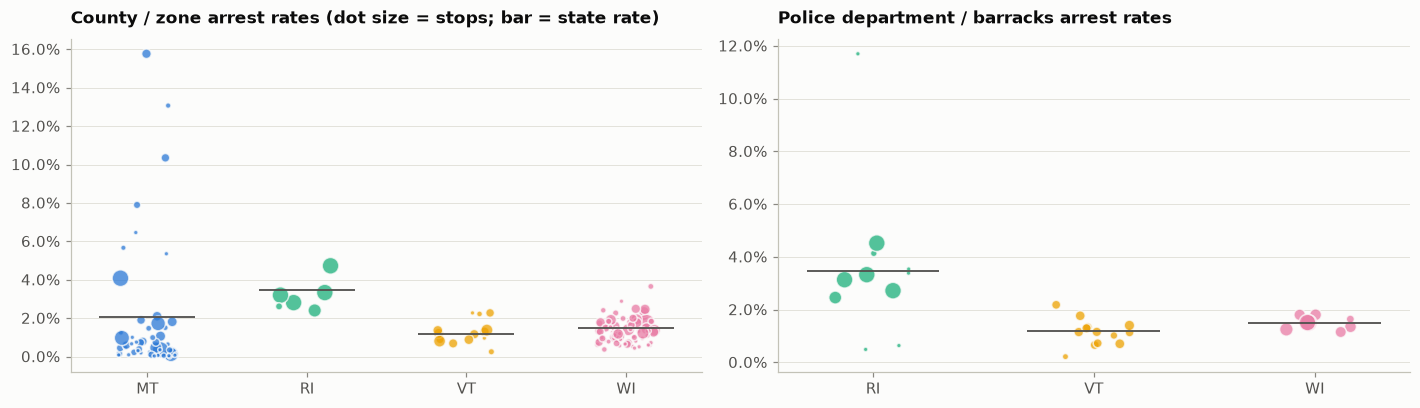

,count,min,50%,max
state,,,,
MT,54,0.00%,0.47%,15.77%
RI,6,2.40%,3.01%,4.73%
VT,14,0.26%,1.19%,2.28%
WI,70,0.37%,1.31%,3.66%


,state,geo_unit,mean,size
36,MT,Powell County,15.8%,"23,506"
16,MT,Glacier County,13.1%,"8,019"
10,MT,Deer Lodge County,10.3%,"19,471"
41,MT,Rosebud County,7.9%,"14,094"
18,MT,Granite County,6.5%,"4,721"


In [16]:
df['police_department'] = df['police_department'].str.replace(r'\.0$', '', regex=True)   # RI: '500' vs '500.0'
df['geo_unit'] = df['county_name'].fillna(df['district'])     # RI has district zones instead of counties

geo = (df.groupby(['state', 'geo_unit'])['is_arrested'].agg(['mean', 'size'])
         .query('size >= 500').reset_index())
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
GEO_STATES = ['MT', 'RI', 'VT', 'WI']     # NV has no location fields
for i, s in enumerate(GEO_STATES):
    g = geo[geo.state == s]
    jitter = np.random.default_rng(0).uniform(-.18, .18, len(g))
    ax.scatter(np.full(len(g), i) + jitter, g['mean'], s=np.clip(g['size'] / 600, 9, 120),
               color=STATE_COLOR[s], alpha=.75, edgecolor=SURFACE, linewidth=1)
    ax.hlines(STATE_BASE[s], i - .3, i + .3, color=INK2, lw=1.2)
ax.set_xticks(range(len(GEO_STATES)), GEO_STATES); ax.yaxis.set_major_formatter(PCT); ax.grid(axis='x', visible=False)
ax.set_title('County / zone arrest rates (dot size = stops; bar = state rate)')

top_mt = geo[geo.state.eq('MT')].nlargest(5, 'mean')

dept = (df.dropna(subset=['police_department']).groupby(['state', 'police_department'])['is_arrested']
          .agg(['mean', 'size']).query('size >= 500').reset_index())
ax = axes[1]
for i, s in enumerate(['RI', 'VT', 'WI']):
    g = dept[dept.state == s]
    jitter = np.random.default_rng(1).uniform(-.18, .18, len(g))
    ax.scatter(np.full(len(g), i) + jitter, g['mean'], s=np.clip(g['size'] / 600, 9, 120),
               color=STATE_COLOR[s], alpha=.75, edgecolor=SURFACE, linewidth=1)
    ax.hlines(STATE_BASE[s], i - .3, i + .3, color=INK2, lw=1.2)
ax.set_xticks(range(3), ['RI', 'VT', 'WI']); ax.yaxis.set_major_formatter(PCT); ax.grid(axis='x', visible=False)
ax.set_title('Police department / barracks arrest rates')
plt.tight_layout(); plt.show()

display(geo.groupby('state')['mean'].describe()[['count', 'min', '50%', 'max']].style.format('{:.2%}').format('{:.0f}', subset=['count']))
display(top_mt.style.format({'mean': '{:.1%}', 'size': '{:,}'}).set_caption('Highest-arrest-rate MT counties'))

**Observations**
* **MT has extreme between-county variation**: from ~0% to **15.8%** (Powell County, 23.5k stops), with Glacier (13.1%), Deer Lodge (10.3%) and Rosebud (7.9%) also far above the state's 2.1%. Most MT counties sit *below* 1%, so a few high-volume counties drive the MT average.
* Other states are comparatively homogeneous: RI zones span 2.4–4.7%, VT counties 0.3–2.3%, WI counties 0.4–3.7%.
* Department/barracks adds little beyond county in VT and WI (they nearly coincide). RI has one small department code at ~12%.

**Implication:** location matters most in MT. With 50–70 levels per state, **target encoding** (fit inside cross-validation folds to avoid leakage) or a hierarchical state→county encoding suits this better than one-hot.

## 1.9 Feature engineering for the non-standardized fields

Four columns are effectively free text: `search_type_raw`/`search_type`, `stop_outcome` (and its MT-only
`stop_outcome_raw`), and `fine_grained_location`. Each one gets a small, interpretable, **cross-state** representation,
followed by EDA of the result.

### 1.9.1 Search basis: `search_type_raw` → indicator flags

The raw values mix states' vocabularies ("CONSENT SEARCH CONDUCTED", "Consent Search-Rsnbl Suspicion", "Terry Frisk"
vs "STOP AND FRISK (OFFICER SAFETY)"...) and are multi-valued ("Incident to Arrest,Probable Cause"). They are
mapped to 11 legal bases with keyword regexes. `search_type_raw` is used rather than `search_type` because it is a
superset (the normalized column drops VT's and MT's values). A stop can have several bases.

In [17]:
SEARCH_BASES = {
    'consent':              r'(?<!OFFICER )CONSENT',
    'probable_cause':       r'PROBABLE CAUSE',
    'reasonable_suspicion': r'REASONABLE SUSPICION|RSNBL SUSPICION',
    'warrant':              r'WARRANT',
    'incident_to_arrest':   r'INCIDENT TO ARREST',     # post-arrest -> leakage
    'inventory_tow':        r'INVENTORY|/TOW',         # typically post-arrest/impound -> leakage
    'frisk':                r'FRISK',
    'plain_view':           r'PLAIN VIEW',
    'odor':                 r'ODOR',
    'parole_probation':     r'PROBATION|PAROLE',
    'exigent':              r'EXIGENT',
}
st_raw = df['search_type_raw'].str.upper().where(df['search_type_raw'].ne('No Search Conducted'))
for k, pat in SEARCH_BASES.items():
    df['search_' + k] = st_raw.str.contains(pat, regex=True).fillna(False).astype(bool)
SEARCH_COLS = ['search_' + k for k in SEARCH_BASES]
df['search_basis_known'] = st_raw.notna()
df['n_search_bases'] = df[SEARCH_COLS].sum(axis=1)

unmapped = st_raw[st_raw.notna() & df['n_search_bases'].eq(0)].value_counts()
print(f'Raw search values not mapped to any basis: {unmapped.sum()} rows -> {unmapped.to_dict()}')

searched = df['search_conducted_clean'].fillna(False).astype(bool)
cov = pd.DataFrame({'searches (clean flag)': searched.groupby(df.state).sum(),
                    'searches with a basis recorded': (searched & df.search_basis_known).groupby(df.state).sum()})
cov['basis coverage'] = cov.iloc[:, 1] / cov.iloc[:, 0]
display(cov.style.format({'basis coverage': '{:.0%}', 'searches (clean flag)': '{:,}', 'searches with a basis recorded': '{:,}'}))

Raw search values not mapped to any basis: 1 rows -> {'(WINOOSKI) PASSGR SRCH': 1}


,searches (clean flag),searches with a basis recorded,basis coverage
state,,,
MT,"3,026","3,026",100%
NV,0,0,nan%
RI,"17,762","17,762",100%
VT,"3,401","3,401",100%
WI,"166,100","14,164",9%


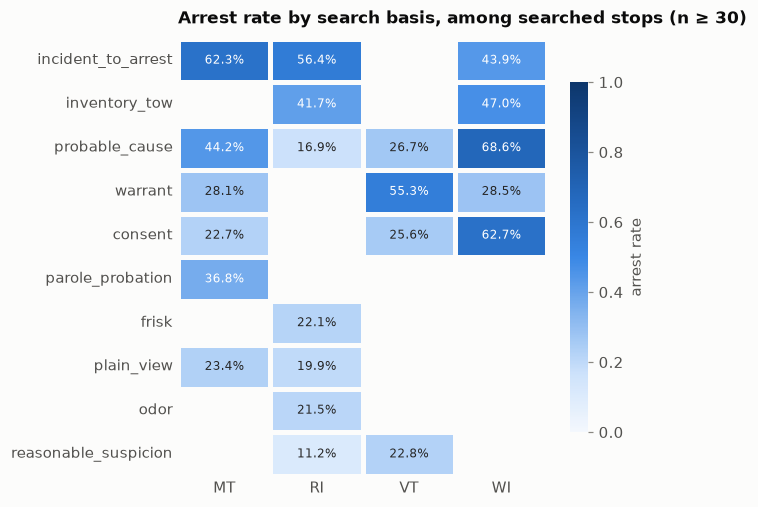

state,MT,RI,VT,WI
consent,"2,240",0,"3,182",357
probable_cause,43,"3,327","2,304","6,812"
reasonable_suspicion,0,"1,715",878,0
warrant,377,0,219,"2,636"
incident_to_arrest,151,"8,759",0,"8,007"
inventory_tow,8,"2,214",0,264
frisk,13,"1,598",0,0
plain_view,137,960,0,0
odor,0,"3,254",0,0
parole_probation,57,0,0,0


In [18]:
# Among stops with a known search basis: arrest rate by basis and state
sb = df[df.search_basis_known]
sb_rate = pd.DataFrame({c.replace('search_', ''): sb[sb[c]].groupby('state')['is_arrested'].agg(['mean', 'size'])
                        .pipe(lambda t: t['mean'].where(t['size'] >= 30)) for c in SEARCH_COLS}).T.reindex(columns=['MT', 'RI', 'VT', 'WI'])
sb_rate = sb_rate.dropna(how='all')
sb_rate = sb_rate.loc[sb_rate.mean(axis=1).sort_values(ascending=False).index]
rate_heatmap(sb_rate, title='Arrest rate by search basis, among searched stops (n ≥ 30)', vmax=1)
plt.tight_layout(); plt.show()

counts = sb[SEARCH_COLS].groupby(sb.state).sum().T
counts.index = counts.index.str.replace('search_', '')
display(counts[counts.sum(axis=1) > 0].style.format('{:,}').set_caption('Number of searches citing each basis'))

**Observations**
* The regex mapping covers every raw value except one VT row ("(Winooski) Passgr Srch").
* The search basis is recorded for **100% of searches in MT, RI and VT** but **only 9% in WI** (14k of 166k). This confirms that WI's `search_conducted` is a different, broader measure.
* **"Incident to arrest"** and **"inventory/tow"** searches happen *because of* an arrest or impound, so they leak the target by definition. Surprisingly, only 44–62% of them have `is_arrested` = True. The arrest may have been of a passenger, or recorded under a different outcome, which suggests the label itself has some noise.
* Among non-leaky bases, **probable-cause searches** are the most arrest-prone (WI 69%, MT 44%), while **consent** searches vary widely by state (MT/VT ~23–26% vs WI 63%). Reasonable-suspicion and frisk searches are the least arrest-prone (11–23%).
* Bases are vocabulary-specific: RI alone uses odor / frisk / reasonable suspicion, MT alone parole/probation, WI alone exigent circumstances. Cross-state comparisons therefore only hold for consent, probable cause and warrant.

### 1.9.2 Stop outcome: `stop_outcome` / `stop_outcome_raw` → standardized severity

`stop_outcome` has 12 state-specific labels ("Arrest Driver", "Arrest for Violation", "Written Warning", "N/D"...).
They are collapsed into an ordered severity scale. Montana's `stop_outcome_raw` is multi-valued
("MISDEMEANOR ARREST,TRAFFIC CITATION,WARNING") and is split into indicators, which also separates misdemeanor from felony arrests.

> As §1.5 showed, this is a **post-outcome field** and is *not* a modeling feature. It is engineered here to understand the
> outcome distribution and to confirm the target's definition per state.

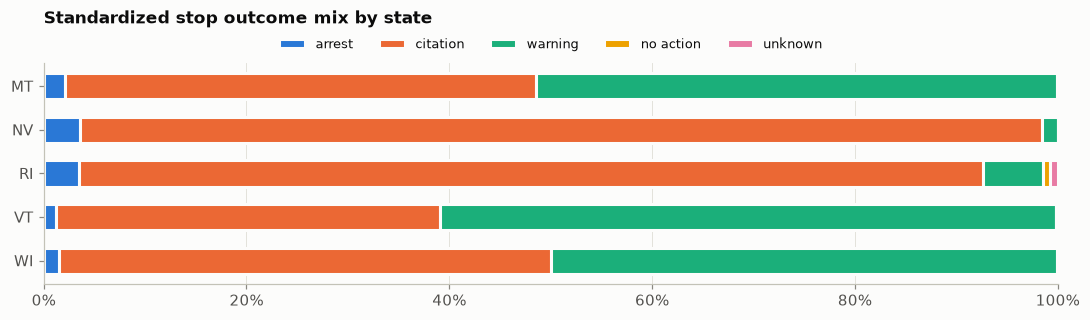

outcome_std,arrest,citation,warning,no action,unknown
state,,,,,
MT,2.1%,46.5%,51.4%,0.0%,0.0%
NV,3.6%,94.9%,1.6%,0.0%,0.0%
RI,3.5%,89.1%,6.0%,0.7%,0.7%
VT,1.2%,37.9%,60.8%,0.0%,0.1%
WI,1.5%,48.5%,49.9%,0.1%,0.0%


MT: any *_ARREST in stop_outcome_raw vs is_arrested


is_arrested,False,True
raw has arrest,,
False,807870,0
True,0,17175


,share of MT arrests with this outcome
misdemeanor_arrest,97.5%
warning,36.8%
traffic_citation,12.5%
felony_arrest,4.0%
faulty_equipment_notice,0.3%
inffraction_arrest,0.2%
no_enforcement_action,0.1%
none_-_jurisdictional_issue,0.0%


In [19]:
OUTCOME_MAP = {
    'Arrest': 'arrest', 'Arrest Driver': 'arrest', 'Arrest Passenger': 'arrest', 'Arrest for Violation': 'arrest',
    'Warrant Arrest': 'arrest', 'Citation': 'citation', 'Written Warning': 'warning', 'Warning': 'warning',
    'Verbal Warning': 'warning', 'Faulty Equipment Notice': 'warning', 'No Action': 'no action', 'N/D': 'unknown',
}
OUTCOME_ORDER = ['arrest', 'citation', 'warning', 'no action', 'unknown']
df['outcome_std'] = pd.Categorical(df['stop_outcome'].map(OUTCOME_MAP).fillna('unknown'), OUTCOME_ORDER, ordered=True)

share = pd.crosstab(df.state, df.outcome_std, normalize='index')
fig, ax = plt.subplots(figsize=(10, 3))
left = np.zeros(len(share))
for i, o in enumerate(OUTCOME_ORDER):
    ax.barh(share.index, share[o], left=left, color=SERIES[i], label=o, height=.6, edgecolor=SURFACE, linewidth=2)
    left += share[o].values
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PCT); ax.grid(axis='y', visible=False); ax.set_xlim(0, 1)
ax.legend(ncol=5, loc='lower center', bbox_to_anchor=(.5, 1.0), fontsize=8.5)
ax.set_title('Standardized stop outcome mix by state', pad=26)
plt.tight_layout(); plt.show()
display(share.style.format('{:.1%}'))

# Montana's multi-valued raw outcome
mt_out = df.loc[mt, 'stop_outcome_raw'].str.get_dummies(sep=',').astype(bool)
mt_out.columns = mt_out.columns.str.lower().str.replace(' ', '_')
arrest_cols = [c for c in mt_out.columns if 'arrest' in c]
print('MT: any *_ARREST in stop_outcome_raw vs is_arrested')
display(pd.crosstab(mt_out[arrest_cols].any(axis=1), df.loc[mt, 'is_arrested'], rownames=['raw has arrest'], colnames=['is_arrested']))
mt_arrests = mt_out[df.loc[mt, 'is_arrested']]
display(mt_arrests.mean().sort_values(ascending=False).to_frame('share of MT arrests with this outcome').style.format('{:.1%}'))

**Observations**
* Outside of arrests, enforcement style differs sharply: **NV (95%) and RI (89%) almost always cite**, while MT, VT and WI split roughly evenly between citations and warnings.
* In MT, the multi-valued raw field matches `is_arrested` exactly: every stop with any "... ARREST" token is an arrest and vice versa. 97.5% of MT arrests are misdemeanors and 4% felonies. 37% of MT arrests *also* list a warning and 12.5% a citation, which is why "most severe outcome" was used to build `stop_outcome`.
* This confirms the leakage conclusion: the outcome fields are the target in another form. `outcome_std` could serve as a **multi-class alternative target** (arrest vs citation vs warning), but it is not a feature.

### 1.9.3 `fine_grained_location` → road class, milepost, intersection, ramp, interstate corridor

Available for MT, VT and WI only (NV and RI have no fine location). The formats differ completely by state:
* **WI** is semi-structured: `"<direction> <highway number> <cross street / milepost>"`, e.g. `"E 094 MP 109"`, `"N 041 CTH B"`.
* **MT / VT** are free text typed by troopers: `"I-90 MM 313 WB"`, `"US HWY 2 EB MM 260"`, `"VT RT 103 & TREBO RD"`, `"browns trace"`.

Rather than trying to geocode, the text is reduced to a few features that plausibly relate to arrest risk:
* **road_class**: interstate / US highway / state highway / county road / local street / unclassified.
  Highway traffic (often through-travelers) and town streets (local residents, nighttime) are policed differently.
* **has_milepost**: a mile-marker reference, meaning a highway stop between exits.
* **is_intersection**: two roads named, i.e. an in-town or junction stop.
* **is_ramp_exit**: ramp or exit mentioned.
* **interstate_id**: which interstate corridor (I-90, I-94, I-15, I-89, I-91...). Corridors can differ, for example drug-trafficking routes.

In [20]:
loc = df['fine_grained_location'].str.upper().str.strip()
loc = loc.mask(loc.isin(['', 'NA', 'NA NA NA']))

# --- WI: structured "<dir> <hwy> <rest>" ---
wi = df.state.eq('WI')
wi_parts = loc[wi].str.extract(r'^(?P<dir>N|S|E|W|NA)\s+(?P<hwy>\S+)\s*(?P<rest>.*)$')
wi_num = pd.to_numeric(wi_parts['hwy'], errors='coerce')
WI_INTERSTATES = {39, 43, 90, 94, 535, 794, 894}
WI_US_HWYS = {2, 8, 10, 12, 14, 18, 41, 45, 51, 53, 61, 63, 141, 151}
wi_class = np.select(
    [wi_num.isin(WI_INTERSTATES), wi_num.isin(WI_US_HWYS), wi_num.notna(),
     (wi_parts['hwy'].str.fullmatch(r'[A-Z]{1,2}') & wi_parts['hwy'].ne('NA')).fillna(False).astype(bool),
     wi_parts['rest'].str.contains(r'\b(?:ST|AVE|RD|LN|DR|BLVD|WAY|CT|PL|PKWY)\b', na=False)],
    ['interstate', 'us_highway', 'state_highway', 'county_road', 'local_street'], default='unclassified')

# --- MT / VT (and generic): keyword rules, first match wins ---
ROAD_RULES = [
    ('interstate',    r'\b(?:I|IH|INTERSTATE)\s?-?\s?\d{2,3}|\bI\d{2,3}[NSEW]?\b'),
    ('us_highway',    r'\bUSH\s?\d|\bUS\s?-?\s?(?:HWY|HIGHWAY|RT|RTE|ROUTE)?\s?-?\s?\d|\bU\.S\.'),
    ('state_highway', r'\bSTH\s?\d|\b(?:MT|VT|SR|S|STATE)\s?-?\s?(?:HWY|HIGHWAY|RT|RTE|ROUTE)?\s?-?\s?\d|\b(?:HWY|HIGHWAY|RT|RTE|ROUTE)\s?-?\s?\d|^\d{1,3}\s+MM'),
    ('county_road',   r'\bCOUNTY\b|\bCTH\b|\bCR\s?-?\s?\d'),
    ('local_street',  r'\b(?:ST|STREET|AVE|AVENUE|RD|ROAD|LN|LANE|DR|DRIVE|BLVD|WAY|CT|PL|PKWY|TRL|TRAIL|HL|HILL|HWY)\b'),
]
generic_class = pd.Series(np.select([loc.str.contains(p, regex=True, na=False) for _, p in ROAD_RULES],
                                    [c for c, _ in ROAD_RULES], default='unclassified'), index=loc.index)
# WI rows with no highway number ("NA NA STH 13") fall back to the keyword rules on the text
generic_class[wi] = np.where(wi_class == 'unclassified', generic_class[wi], wi_class)
df['road_class'] = generic_class.where(loc.notna())

df['has_milepost'] = loc.str.contains(r'\b(?:MM|MP|MILE\s?MARKER|MILEPOST)\s?\d|\d\s?(?:MM|MP)\b|\bMM\d', regex=True).where(loc.notna()).astype('boolean')
df['is_intersection'] = (loc.str.replace('ON/OFF', '', regex=False)
                            .str.contains(r'\s(?:&|AND|X|@|AT)\s|[A-Z0-9]{2,}\s?/\s?[A-Z0-9]{2,}|\bCROSSING\b', regex=True)
                            .where(loc.notna()).astype('boolean'))
df['is_ramp_exit'] = loc.str.contains(r'\b(?:EXIT|RAMP|ON/OFF)\b', regex=True).where(loc.notna()).astype('boolean')
# two named roads with no highway marker ("PALMER AND GREAT NORTHERN") are town intersections
df.loc[df['road_class'].eq('unclassified') & df['is_intersection'].fillna(False), 'road_class'] = 'local_street'

iid = loc.str.extract(r'\b(?:I|IH|INTERSTATE)\s?-?\s?(\d{2,3})\b|\bI(\d{2,3})[NSEW]', expand=True)
interstate_id = iid[0].fillna(iid[1])
wi_iid = wi_num.where(wi_num.isin(WI_INTERSTATES))
interstate_id[wi] = wi_iid.astype('Int64').astype(str).where(wi_iid.notna(), interstate_id[wi])
df['interstate_id'] = ('I-' + interstate_id.str.lstrip('0')).where(df['road_class'].eq('interstate'))

ORDER = ['interstate', 'us_highway', 'state_highway', 'county_road', 'local_street', 'unclassified']
has_loc = df['road_class'].notna()
display(pd.crosstab(df.loc[has_loc, 'state'], df.loc[has_loc, 'road_class'], normalize='index')[ORDER]
        .style.format('{:.1%}').set_caption('Road class distribution (stops with a fine_grained_location)'))
print('Random sample of still-unclassified values:')
for s in ['MT', 'VT', 'WI']:
    u = df.loc[df.state.eq(s) & df.road_class.eq('unclassified'), 'fine_grained_location']
    print(f'  {s}:', u.sample(min(10, len(u)), random_state=0).tolist())

road_class,interstate,us_highway,state_highway,county_road,local_street,unclassified
state,,,,,,
MT,30.3%,22.2%,23.9%,0.1%,16.9%,6.6%
VT,34.2%,17.3%,24.6%,0.3%,22.5%,1.1%
WI,43.2%,23.1%,21.1%,4.6%,6.4%,1.6%


Random sample of still-unclassified values:
  MT: ['0015197SB', 'MONARCH SCHOOL IN HERON', 'HIGWWAY 310, MP 22 NB', 'BLU MT', 'BUS LOOP/7 MI CRK', 'SEC 223 MP 44 NB', 'HARLEY DAVIDSON', '90-292 WB', 'MAIN EB', 'E VALLEY CENTER MM2']
  VT: ['MERCHANTS ROW', 'Oakland Station near RR tracks', '7 WESTON HTS', 'VAST 7N', 'LOWER MAIN E', 'mm 88', 'Lynburke Motel', 'ETHAN ALLEN HIGHWAY', 'BROWNS TRACE', 'LAKE MEMPHREMAGOG']
  WI: ['NA NA V', 'NA NA LINCOLN', 'NA NA MP 89', 'NA NA HIGHWAY ON/OFF RAMP', 'NA NA MP 174', 'NA NA MP 89', 'NA NA MP 102', 'NA NA HIGHWAY ON/OFF RAMP', 'NA NA EMILIE', 'NA NA HILLCREST']


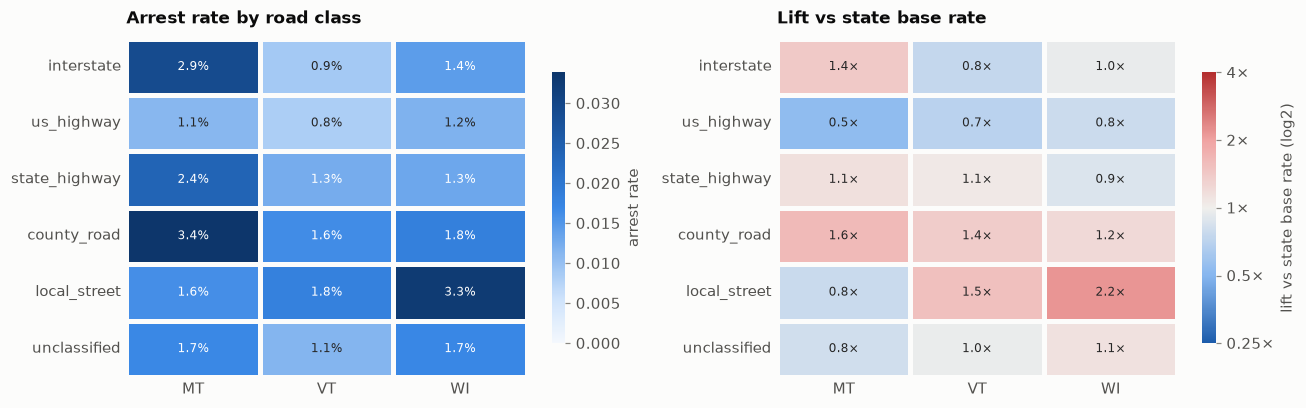

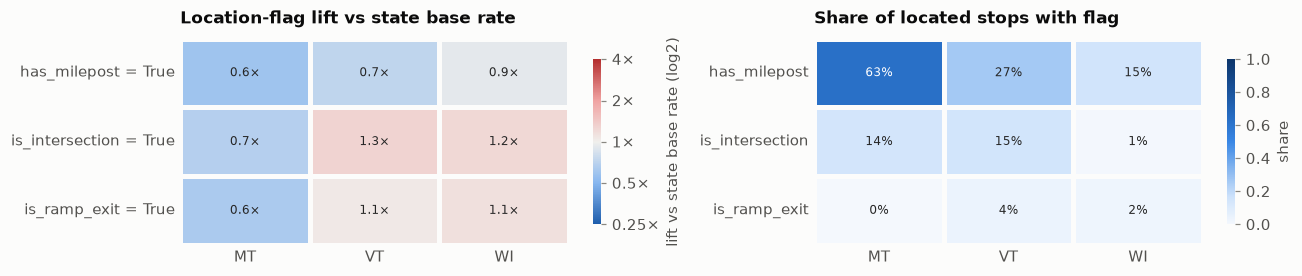

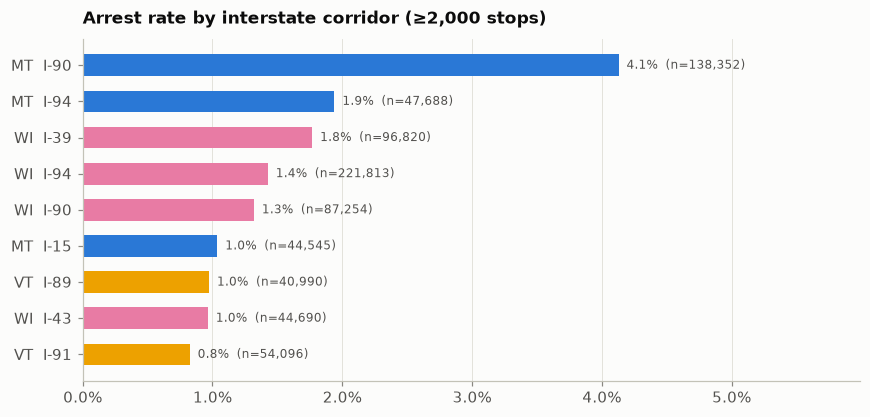

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rc_rate, _ = rate_table(df[has_loc], 'road_class')
rc_rate = rc_rate.reindex(ORDER)
rate_heatmap(rc_rate, axes[0], 'Arrest rate by road class')
lift_heatmap(rc_rate, axes[1], 'Lift vs state base rate', lim=2)
plt.tight_layout(); plt.show()

fl = pd.DataFrame({f'{c} = True': df[df[c].eq(True)].groupby('state')['is_arrested'].mean()
                   for c in ['has_milepost', 'is_intersection', 'is_ramp_exit']}).T.reindex(columns=['MT', 'VT', 'WI'])
fl_base = pd.DataFrame({f'{c} = True': df[df[c].eq(True)].groupby('state').size()
                        for c in ['has_milepost', 'is_intersection', 'is_ramp_exit']}).T.reindex(columns=['MT', 'VT', 'WI'])
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
lift_heatmap(fl.where(fl_base >= 300), axes[0], 'Location-flag lift vs state base rate', lim=2)
share_true = df[has_loc].groupby('state')[['has_milepost', 'is_intersection', 'is_ramp_exit']].mean().T.astype(float)
_heat(share_true, share_true.map(lambda v: f'{v:.0%}'), axes[1], SEQ, 'Share of located stops with flag', 'share', vmin=0, vmax=1)
plt.tight_layout(); plt.show()

corr = (df.dropna(subset=['interstate_id']).groupby(['state', 'interstate_id'])['is_arrested']
          .agg(['mean', 'size']).query('size >= 2000').reset_index().sort_values('mean'))
fig, ax = plt.subplots(figsize=(8, .32 * len(corr) + 1))
labels = corr.state + '  ' + corr.interstate_id
ax.barh(labels, corr['mean'], color=[STATE_COLOR[s] for s in corr.state], height=.6)
for y, (r, n) in enumerate(zip(corr['mean'], corr['size'])):
    ax.text(r, y, f'  {r:.1%}  (n={n:,})', va='center', fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(PCT); ax.grid(axis='y', visible=False); ax.set_xlim(0, corr['mean'].max() * 1.45)
ax.set_title('Arrest rate by interstate corridor (≥2,000 stops)')
plt.tight_layout(); plt.show()

**Observations**
* The rules classify all but a small residual of located stops. What remains is genuine free text: landmarks ("LAKE MEMPHREMAGOG", "HARLEY DAVIDSON"), typos ("HIGWWAY 310") and bare mileposts with no road named.
* **Road class matters, and differently by state**:
  * In **WI and VT, local streets carry the highest risk** (2.2× and 1.5×). Town stops at night are more likely to involve impairment than highway speed enforcement.
  * In **MT, interstates are 1.4×** and US highways only 0.5×.
  * **County roads** run 1.2–1.6× everywhere.
* **Milepost stops** (between-exit highway stops, mostly speed enforcement) are *below* base in every state (0.6–0.9×). Intersection and ramp flags carry small, state-inconsistent effects.
* **Interstate corridor** is informative: MT's **I-90 runs at 4.1%**, twice MT's base and 4× MT's I-15 (1.0%). I-90 passes through Powell and Deer Lodge counties, the high-arrest counties from §1.8, so the corridor and county effects overlap and largely tell the same story.

### 1.9.4 Vehicle age (MT and WI)

MT records `vehicle_year`; WI buries the model year at the end of `vehicle_type` (`"HONDA CIVIC 2008"`). Vehicle age
at the time of the stop is a plausible socioeconomic proxy.

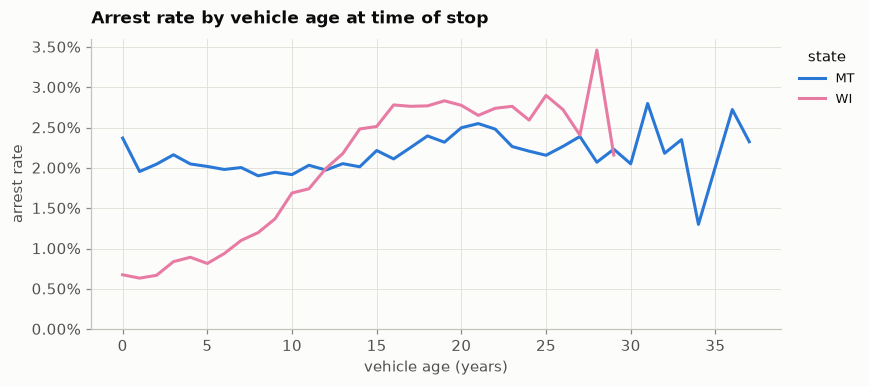

In [22]:
wi_vyear = pd.to_numeric(df.loc[wi, 'vehicle_type'].str.extract(r'(\d{4})\s*$')[0], errors='coerce')
vyear = df['vehicle_year'].copy()
vyear[wi] = wi_vyear
df['vehicle_age'] = (df['year'] - vyear).where(lambda a: a.between(0, 40))

va_rate, _ = rate_table(df.dropna(subset=['vehicle_age']), 'vehicle_age', min_n=500)
rate_lines(va_rate[['MT', 'WI']], title='Arrest rate by vehicle age at time of stop', xlabel='vehicle age (years)')
plt.tight_layout(); plt.show()

**Observations**
* **WI shows a strong, monotonic gradient**: drivers of new vehicles are arrested ~0.3% of the time, rising steadily to ~2.5% for vehicles 15+ years old (an ~8× spread). Vehicle age is plausibly a socioeconomic proxy and one of WI's better pre-stop features, which matters because WI lacks driver age.
* **MT is flat** (~2% at every vehicle age). The same feature is strong in one state and useless in another, which again argues for state-aware modeling (per-state models or state interactions).

## 1.10 Relationships between features

### Feature ↔ feature association (Cramér's V)
Cramér's V (0 = independent, 1 = perfectly associated) works for any pair of categorical variables, so numeric features are
binned. **Missing is kept as its own level**, so the matrix shows both value associations and shared-missingness
patterns. It is computed on a 400k-row random sample, which is plenty for stable estimates.

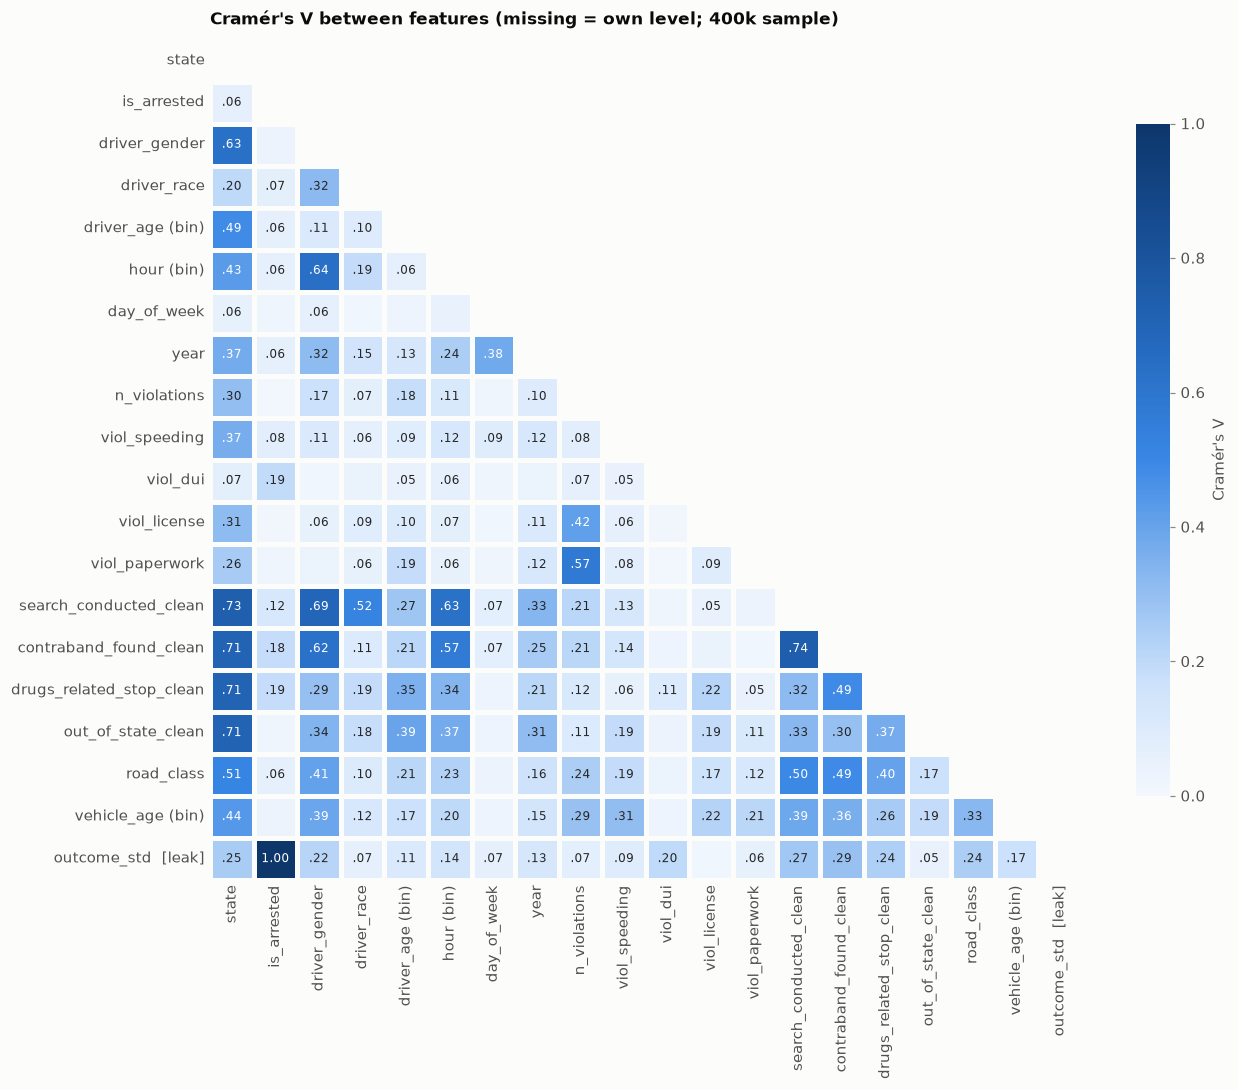

In [23]:
samp = df.sample(400_000, random_state=42)
assoc_feats = {
    'state': samp.state,
    'is_arrested': samp.is_arrested,
    'driver_gender': samp.driver_gender,
    'driver_race': samp.driver_race,
    'driver_age (bin)': pd.cut(samp.driver_age, [15, 20, 25, 30, 40, 50, 60, 100]),
    'hour (bin)': pd.cut(samp.hour, [-1, 5, 9, 15, 19, 23]),
    'day_of_week': samp.day_of_week,
    'year': samp.year,
    'n_violations': samp.n_violations.clip(upper=4),
    'viol_speeding': samp.viol_speeding,
    'viol_dui': samp.viol_dui,
    'viol_license': samp.viol_license,
    'viol_paperwork': samp.viol_paperwork,
    'search_conducted_clean': samp.search_conducted_clean,
    'contraband_found_clean': samp.contraband_found_clean,
    'drugs_related_stop_clean': samp.drugs_related_stop_clean,
    'out_of_state_clean': samp.out_of_state_clean,
    'road_class': samp.road_class,
    'vehicle_age (bin)': pd.cut(samp.vehicle_age, [-1, 3, 7, 12, 20, 41]),
    'outcome_std  [leak]': samp.outcome_std,
}
assoc = {k: v.astype(object).where(v.notna(), 'MISSING').astype(str) for k, v in assoc_feats.items()}
names = list(assoc)
V = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = cramers_v(assoc[a], assoc[b])

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(V, dtype=bool))
_heat(V, V.map(lambda v: f'{v:.2f}'.lstrip('0') if v >= .05 else ''), ax, SEQ,
      "Cramér's V between features (missing = own level; 400k sample)", "Cramér's V", vmin=0, vmax=1, mask=mask)
plt.tight_layout(); plt.show()

**Observations**
* **`state` is strongly associated with almost everything** (V = 0.4–0.73 for gender, age, hour, the search/contraband/out-of-state flags, road class and vehicle age). That association comes mostly through **missingness**: "MISSING" is a level here, and which fields are missing is set by state.
* Several large feature-to-feature values are the **same artifact**: gender ↔ hour (0.64), gender ↔ search (0.69) and hour ↔ search (0.63) are high because NV is missing gender, hour *and* the cleaned search flag together. They are not behavioral relationships.
* The genuine value relationships are moderate: contraband ↔ search (0.74, partly MT's copied column), n_violations ↔ paperwork/license (0.42–0.57, since multi-violation stops are usually paperwork stacks), and search ↔ race (0.52).
* **Pooled association with `is_arrested` is weak for every single feature** (all ≤ 0.2 except the leaky `outcome_std` = 1.0). Arrest is a rare event driven by a few specific signals (DUI, warrants, searches) rather than by broad demographic shifts.

**Implication:** multicollinearity is driven by shared missingness, so models that treat missing as informative (gradient-boosted trees) will implicitly learn state from the missingness pattern. That is fine for in-distribution accuracy, but it makes state the hidden driver of many splits. Including `state` explicitly makes this transparent.

### Strength of each feature's relationship with `is_arrested`, *within* each state

This is the most direct answer to "which features matter, and does that differ by state". Each cell is Cramér's V between
the feature and `is_arrested` computed **inside one state only** (blank = feature not recorded in that state). Post-stop/leaky
features are listed separately at the bottom for reference.

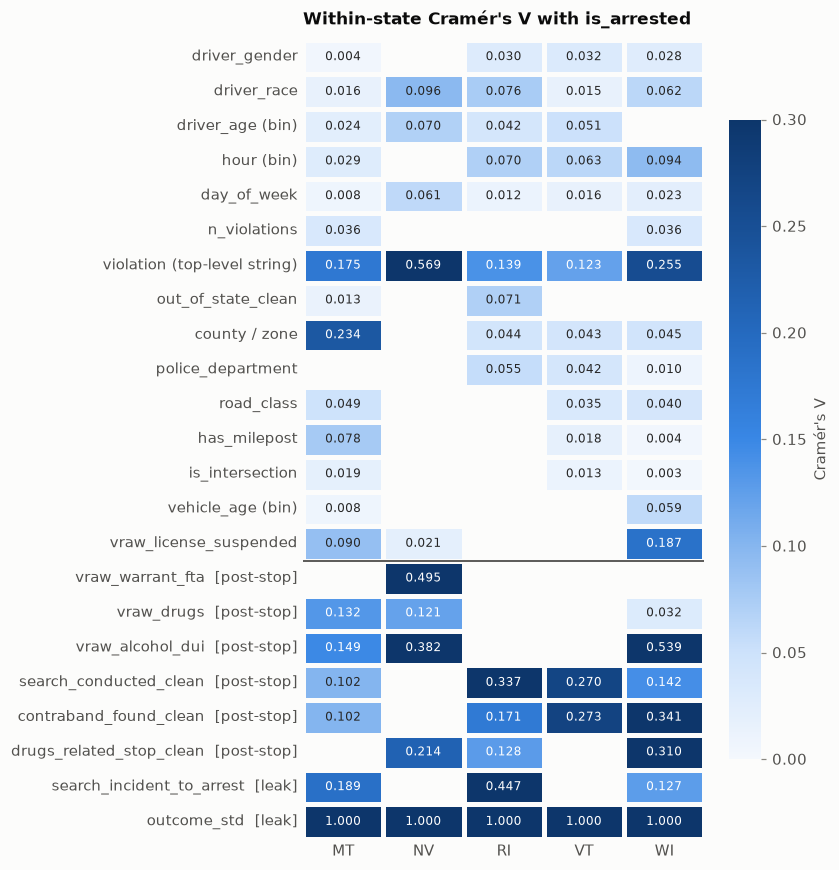

In [24]:
within_feats = {
    'driver_gender': lambda d: d.driver_gender,
    'driver_race': lambda d: d.driver_race,
    'driver_age (bin)': lambda d: pd.cut(d.driver_age, [15, 20, 25, 30, 40, 50, 60, 100]),
    'hour (bin)': lambda d: pd.cut(d.hour, [-1, 5, 9, 15, 19, 23]),
    'day_of_week': lambda d: d.day_of_week,
    'n_violations': lambda d: d.n_violations.clip(upper=4),
    'violation (top-level string)': lambda d: d.violation.where(d.violation.map(d.violation.value_counts()) >= 200, 'rare'),
    'out_of_state_clean': lambda d: d.out_of_state_clean,
    'county / zone': lambda d: d.geo_unit,
    'police_department': lambda d: d.police_department,
    'road_class': lambda d: d.road_class,
    'has_milepost': lambda d: d.has_milepost,
    'is_intersection': lambda d: d.is_intersection,
    'vehicle_age (bin)': lambda d: pd.cut(d.vehicle_age, [-1, 3, 7, 12, 20, 41]),
    'vraw_license_suspended': lambda d: d.vraw_license_suspended.where(d.state.isin(['MT', 'NV', 'WI'])),
    'vraw_warrant_fta  [post-stop]': lambda d: d.vraw_warrant_fta.where(d.state.isin(['MT', 'NV', 'WI'])),
    'vraw_drugs  [post-stop]': lambda d: d.vraw_drugs.where(d.state.isin(['MT', 'NV', 'WI'])),
    'vraw_alcohol_dui  [post-stop]': lambda d: d.vraw_alcohol_dui.where(d.state.isin(['MT', 'NV', 'WI'])),
    'search_conducted_clean  [post-stop]': lambda d: d.search_conducted_clean,
    'contraband_found_clean  [post-stop]': lambda d: d.contraband_found_clean,
    'drugs_related_stop_clean  [post-stop]': lambda d: d.drugs_related_stop_clean,
    'search_incident_to_arrest  [leak]': lambda d: d.search_incident_to_arrest.where(d.search_basis_known),
    'outcome_std  [leak]': lambda d: d.outcome_std,
}
W = pd.DataFrame(index=list(within_feats), columns=STATES, dtype=float)
for s in STATES:
    d = df[df.state == s]
    for name, f in within_feats.items():
        x = f(d)
        ok = x.notna()
        if ok.sum() >= 1000 and x[ok].nunique() > 1:
            W.loc[name, s] = cramers_v(x[ok].astype(str), d.loc[ok, 'is_arrested'])

fig, ax = plt.subplots(figsize=(7.5, 8))
_heat(W, W.map(lambda v: '' if pd.isna(v) else f'{v:.3f}'), ax, SEQ,
      "Within-state Cramér's V with is_arrested", "Cramér's V", vmin=0, vmax=.3)
ax.axhline(15, color=INK2, lw=1.2)     # rows below the line are post-stop / leaky
plt.tight_layout(); plt.show()

**Observations** (rows above the line are known at or before the start of the stop; rows below are determined during or after it)
* **The violation description is the strongest pre-stop feature everywhere** (V 0.12–0.57). It is extreme in NV only because NV's "Other" hides warrant (FTA) charges.
* **Location is decisive in MT only** (county V = 0.23, plus milepost and road class). Elsewhere county/zone is weak (≤ 0.05).
* **Hour of day** is a moderate signal wherever it exists (RI, VT, WI: 0.06–0.09). **Race** is moderate in NV, RI and WI (0.06–0.10), weak in MT/VT. **Vehicle age** is moderate in WI (0.06) and nil in MT.
* **Suspended/revoked license** (from `violation_raw`) is the strongest single routine signal in WI (0.19) and solid in MT (0.09). It comes from a records check early in the stop, so it is a reasonable feature for most use cases.
* The **post-stop features dominate**: alcohol charges (WI 0.54, NV 0.38), warrant/FTA (NV 0.50), search (0.10–0.34), contraband (0.10–0.34), drug-related (0.13–0.31), and search-incident-to-arrest (RI 0.45). If they are allowed, they will drive the model.
* Every state has a different set of available features **and** different strengths for the same feature. This is the clearest evidence that one pooled model without state context will blur together five different relationships.

## 1.11 EDA summary & implications for modeling

**Target**
* `is_arrested` is rare (2.34%, 79k positives) and its base rate varies 3× by state (VT 1.2% → NV 3.6%). Use stratified splits by **state × target**, report metrics **per state** as well as pooled, and favor PR-AUC / average precision over accuracy.
* **NV labels before July 2014 are unreliable** (0.39% arrest rate vs 6.05% after, plus a 59.6k-stop block stamped 2012-02-14 with zero arrests). Drop that window, or at minimum flag it.

**Leakage, by tier (decide the prediction point first)**
| tier | features | treatment |
|---|---|---|
| target in disguise | `stop_outcome`, `stop_outcome_raw`, `outcome_std`, search basis *incident to arrest* / *inventory-tow* | always exclude |
| decided during the stop | `search_conducted`, `contraband_found`, `drugs_related_stop`, other search bases, `violation_raw` warrant/drug/alcohol charges (and therefore `viol_dui`, `viol_other`) | include only if scoring completed stop records; otherwise exclude |
| known at stop start | driver age/gender/race, time, date, location, road class, routine violations, vehicle age, out-of-state | candidate features |

**Data quality fixes carried forward**
* Treat placeholder booleans as missing (NV search/contraband/out-of-state; MT & VT drugs-related; VT & WI out-of-state; MT contraband = copy of search).
* Reset the parquet index (it restarts per state). Normalize RI `police_department` ("500" vs "500.0"). Round the stray non-integer age.
* WI's `search_conducted` means something different from the other states' (16% of stops, only 9% with a basis).

**Engineered features that showed signal**
* `viol_*` indicators + `n_violations` (multi-label split of `violation`).
* `vraw_*` keyword flags from `violation_raw`, especially `vraw_license_suspended` as a *pre-arrest* routine signal.
* `road_class`, `has_milepost`, `interstate_id` from `fine_grained_location` (MT, VT, WI). The search-basis flags from `search_type_raw` and the `outcome_std` / MT arrest-type flags from `stop_outcome(_raw)` are mainly diagnostic.
* `hour` / night / weekend, `driver_age`, and `vehicle_age` (MT `vehicle_year`, WI parsed from `vehicle_type`).

**Handling the state discrepancies**
* Feature availability and feature meaning both differ by state, and missingness is a near-perfect state proxy. Recommended approach: a single gradient-boosted model with `state` as an explicit feature and native missing-value handling, so it can learn state-specific interactions. Benchmark it against per-state models (feasible for every state: the smallest, VT, still has 3.3k positives) and check that the pooled model does not underperform in low-base-rate states (VT, WI).
* High-cardinality location (`county`, `police_department`, `interstate_id`) is best target-encoded within CV folds. Location matters chiefly in MT.
* Race and gender are predictive but are protected attributes. Decide deliberately whether to include them, and audit predictions for disparate impact across groups either way.

# 2. Validating the arrest rate over time & removing outlier periods

Section 1 showed that some states' arrest rates move in ways that look like **recording artifacts** rather than real change
(NV's 0% → 6% jump, MT's 7.5% partial 2009). This section validates the rate year by year and month by month for each state,
and removes periods whose rate is not credible. The rules **prefer the most recent years**: recent data is the best guide to
how a model will be used, and in every state the recent years are the stable ones.

Approach:
1. **Yearly validation**: rate, volume, months covered, a 95% confidence interval and year-over-year change per state.
2. **Monthly distribution**: monthly rates are compared against a **recent reference window** (the latest 3 calendar years of each state).
   The comparison uses a robust z-score: `z = (rate − median_ref) / (1.4826 · MAD_ref)`. Median and MAD are not distorted by the outliers themselves.
3. **Outlier rule**:
   * A month is *bad* if `|z| > 3.5` (the standard Iglewicz–Hoaglin cut-off) or it has fewer than 500 stops. Low-volume months are typically
     ramp-up periods where only a selection of records (often arrests) was captured.
   * A **sustained break**, at least 3 consecutive bad months, means the recording regime itself was different. Everything up to and
     including the **latest** sustained break is dropped, keeping the recent stable window.
   * **Isolated** bad months (runs shorter than 3) inside the kept window are flagged and, by default, dropped too.
   * Stops with no date (109 rows) cannot be placed in time, so they cannot be validated and are dropped.

In [25]:
from scipy.stats import norm

MIN_MONTH_N    = 500    # months with fewer stops are treated as unreliable
Z_CUT          = 3.5    # robust z threshold
REF_YEARS      = 3      # reference window = latest N calendar years of each state
MIN_RUN        = 3      # consecutive bad months that constitute a structural break
DROP_ISOLATED  = True   # also drop isolated outlier months inside the kept window

def wilson_ci(k, n, alpha=.05):
    z = norm.ppf(1 - alpha / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

dated = df.dropna(subset=['stop_date'])
print(f'Stops without a date (dropped): {df.stop_date.isna().sum():,} '
      f'({df[df.stop_date.isna()].state.value_counts().to_dict()})')

Stops without a date (dropped): 109 ({'WI': 86, 'NV': 12, 'MT': 11})


## 2.1 Yearly validation

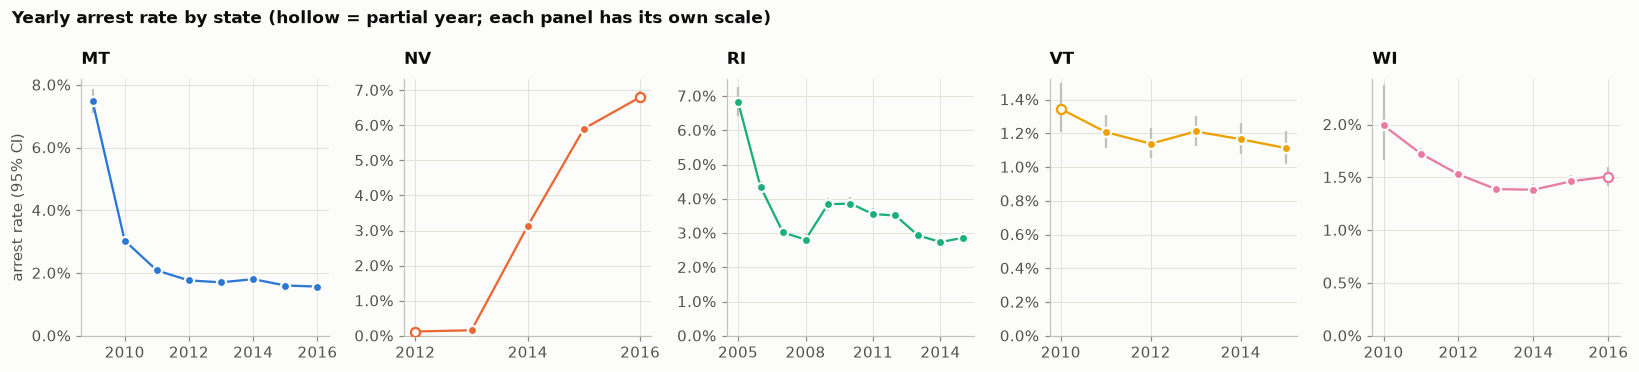

In [26]:
yearly = (dated.groupby(['state', dated.stop_date.dt.year.rename('year')])
               .agg(stops=('is_arrested', 'size'), arrests=('is_arrested', 'sum'),
                    months=('stop_date', lambda d: d.dt.to_period('M').nunique())))
yearly['rate'] = yearly.arrests / yearly.stops
yearly['ci_low'], yearly['ci_high'] = wilson_ci(yearly.arrests, yearly.stops)
yearly['yoy_change_pp'] = yearly.groupby('state')['rate'].diff() * 100

# each year's rate relative to the pooled rate of the state's latest REF_YEARS years
# (a ratio rather than a z-score: 3 yearly points are too few for a stable spread estimate)
def _vs_recent(g):
    years = g.index.get_level_values('year')
    ref = g[years > years.max() - REF_YEARS]
    return g['rate'] / (ref.arrests.sum() / ref.stops.sum())
yearly['vs_recent'] = yearly.groupby('state', group_keys=False).apply(_vs_recent)

display(yearly.style.format({'stops': '{:,}', 'arrests': '{:,}', 'rate': '{:.2%}', 'ci_low': '{:.2%}', 'ci_high': '{:.2%}',
                             'yoy_change_pp': '{:+.2f}', 'vs_recent': '{:.2f}×'}, na_rep='')
              .background_gradient(subset=['vs_recent'], cmap=DIV, gmap=np.log2(yearly['vs_recent']), vmin=-2, vmax=2))

fig, axes = plt.subplots(1, len(STATES), figsize=(15, 3.4))
for ax, s in zip(axes, STATES):
    y = yearly.loc[s]
    full = y.months == 12
    ax.errorbar(y.index, y.rate, yerr=[y.rate - y.ci_low, y.ci_high - y.rate], fmt='none', ecolor=AXIS, elinewidth=1.5, capsize=0)
    ax.plot(y.index, y.rate, color=STATE_COLOR[s], lw=1.5)
    ax.scatter(y.index[full], y.rate[full], color=STATE_COLOR[s], s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(y.index[~full], y.rate[~full], facecolor=SURFACE, edgecolor=STATE_COLOR[s], s=36, zorder=3, linewidth=1.5)
    ax.set_title(s); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1)); ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
axes[0].set_ylabel('arrest rate (95% CI)')
fig.suptitle('Yearly arrest rate by state (hollow = partial year; each panel has its own scale)', x=.01, ha='left',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

**Observations**
* **VT is the only state that is stable throughout**: its yearly rate stays between 1.11% and 1.34%, with every year within about 15% of its recent level.
* **MT, RI and WI all start high and settle.** MT's 2009 rate (7.5%) is about 4.5× its recent level and 2010 is still about 1.8×. RI's 2005 (6.8%) is about 2.4×. WI's tiny 2010 (6.0k stops across 12 months, 2.0%) is elevated too. In each case the confidence intervals are narrow enough that the gaps are not sampling noise.
* **NV runs the other way**: 2012–2013 sit at about 3% of NV's recent level, the missing-arrest problem found in §1.4.
* Year-level numbers hide *where* inside a year the break happens: MT's 2009 volume ramps from about 10 stops/month up to about 10k, and NV changes regime in mid-2014. The monthly view below finds the exact cut points.

## 2.2 Monthly distribution and outlier detection

Monthly rates give each state 60–130 observations, enough to see its typical spread. The reference band below is
`median_ref ± 3.5 robust SD` from each state's latest 3 years.

In [27]:
monthly = (dated.groupby(['state', dated.stop_date.dt.to_period('M').rename('month')])['is_arrested']
                .agg(stops='size', rate='mean').reset_index())

parts = []
for s, g in monthly.groupby('state'):
    g = g.sort_values('month').reset_index(drop=True)
    vol_ok = g.stops >= MIN_MONTH_N
    ref = g[vol_ok & (g.month.dt.year > g.month.dt.year.max() - REF_YEARS)]
    med = ref.rate.median()
    mad = 1.4826 * (ref.rate - med).abs().median()
    g['ref_median'], g['ref_sd'] = med, mad
    g['z'] = (g.rate - med) / mad
    g['low_volume'] = ~vol_ok
    g['bad'] = (g.z.abs() > Z_CUT) | g.low_volume
    run_id = (g.bad != g.bad.shift()).cumsum()
    g['sustained'] = g.bad & (g.groupby(run_id)['bad'].transform('size') >= MIN_RUN)
    cut = g.index[g.sustained].max() if g.sustained.any() else -1      # latest structural break
    g['status'] = np.select([g.index <= cut, g.bad], ['before break', 'isolated outlier'], default='kept')
    parts.append(g)
monthly = pd.concat(parts, ignore_index=True)
if not DROP_ISOLATED:
    monthly.loc[monthly.status.eq('isolated outlier'), 'status'] = 'kept (flagged)'
monthly['keep'] = monthly.status.str.startswith('kept')

ref_tbl = monthly.groupby('state').agg(reference_median=('ref_median', 'first'), robust_sd=('ref_sd', 'first'),
                                       months=('month', 'size'), bad_months=('bad', 'sum'),
                                       kept_from=('month', lambda m: m[monthly.loc[m.index, 'keep']].min()),
                                       kept_to=('month', lambda m: m[monthly.loc[m.index, 'keep']].max()))
ref_tbl['band_low'] = ref_tbl.reference_median - Z_CUT * ref_tbl.robust_sd
ref_tbl['band_high'] = ref_tbl.reference_median + Z_CUT * ref_tbl.robust_sd
display(ref_tbl.style.format({'reference_median': '{:.2%}', 'robust_sd': '{:.2%}', 'band_low': '{:.2%}', 'band_high': '{:.2%}'}))

iso = monthly[monthly.status.isin(['isolated outlier', 'kept (flagged)'])]
display(iso[['state', 'month', 'stops', 'rate', 'z']].style.format({'stops': '{:,}', 'rate': '{:.2%}', 'z': '{:+.1f}'})
        .set_caption('Isolated outlier months inside the kept window'))

,reference_median,robust_sd,months,bad_months,kept_from,kept_to,band_low,band_high
state,,,,,,,,
MT,1.66%,0.25%,96,27,2010-12,2016-12,0.80%,2.51%
NV,5.50%,1.31%,48,21,2014-05,2016-05,0.93%,10.07%
RI,2.88%,0.49%,132,17,2006-02,2015-12,1.17%,4.58%
VT,1.21%,0.20%,66,0,2010-07,2015-12,0.52%,1.89%
WI,1.41%,0.17%,77,12,2010-12,2016-05,0.83%,1.99%


,state,month,stops,rate,z
25,MT,2011-02,"7,950",2.86%,+4.9
27,MT,2011-04,"10,458",2.51%,+3.5
31,MT,2011-08,"9,958",2.53%,+3.6
43,MT,2012-08,"9,942",2.73%,+4.4
162,RI,2006-07,"4,663",5.06%,+4.5
167,RI,2006-12,"4,401",4.64%,+3.6
203,RI,2009-12,"3,050",5.48%,+5.3
205,RI,2010-02,"3,594",4.59%,+3.5
354,WI,2011-01,"17,457",2.02%,+3.7


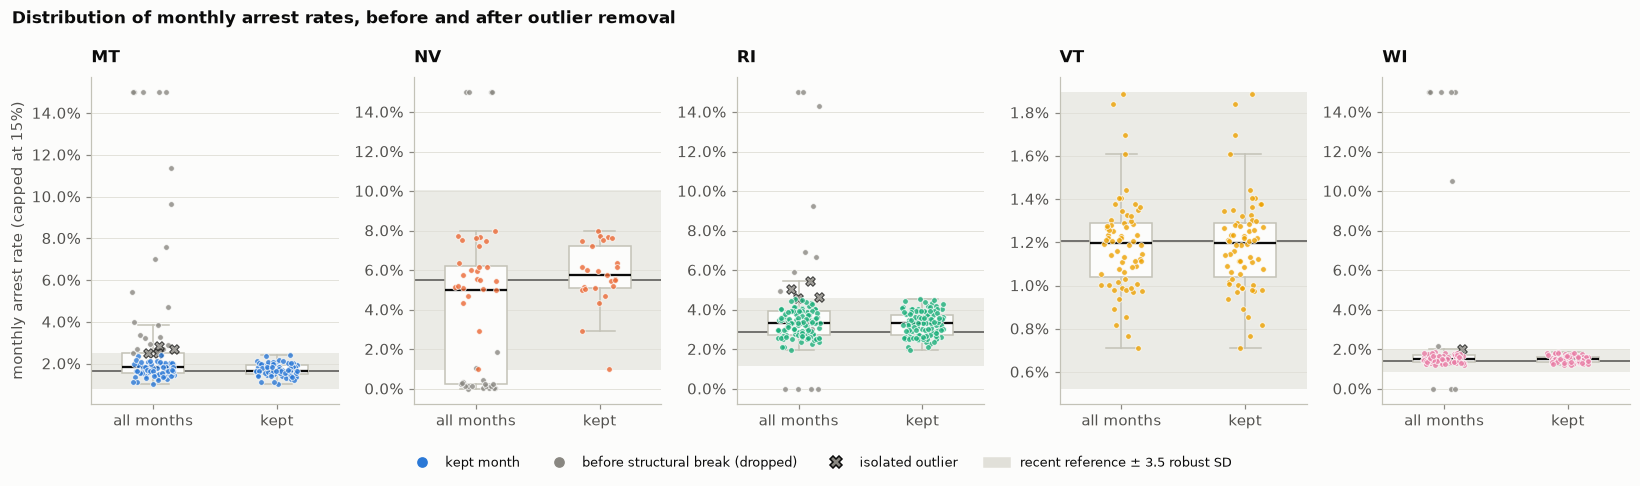

In [28]:
STATUS_STYLE = {'kept': dict(marker='o'), 'kept (flagged)': dict(marker='X'),
                'isolated outlier': dict(marker='X'), 'before break': dict(marker='o')}

fig, axes = plt.subplots(1, len(STATES), figsize=(15, 4.2))
rng = np.random.default_rng(0)
for ax, s in zip(axes, STATES):
    g = monthly[monthly.state == s]
    med, sd = g.ref_median.iloc[0], g.ref_sd.iloc[0]
    ax.axhspan(med - Z_CUT * sd, med + Z_CUT * sd, color=GRID, alpha=.6, lw=0)
    ax.axhline(med, color=INK2, lw=1)
    for x, subset, label in [(0, g, 'all months'), (1, g[g.keep], 'kept')]:
        ax.boxplot(subset.rate, positions=[x], widths=.5, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=SURFACE, edgecolor=AXIS), medianprops=dict(color=INK, lw=1.5),
                   whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
        for status, pts in subset.groupby('status'):
            colour = STATE_COLOR[s] if status.startswith('kept') else MUTED
            ax.scatter(x + rng.uniform(-.17, .17, len(pts)), pts.rate.clip(upper=.15), s=14 if status != 'isolated outlier' else 40,
                       color=colour, alpha=.8, edgecolor=SURFACE if status != 'isolated outlier' else INK, linewidth=.6,
                       zorder=3, **STATUS_STYLE[status])
    ax.set_xticks([0, 1], ['all months', 'kept']); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1)); ax.set_title(s)
axes[0].set_ylabel('monthly arrest rate (capped at 15%)')
handles = [mpl.lines.Line2D([], [], ls='', marker='o', color=SERIES[0], label='kept month'),
           mpl.lines.Line2D([], [], ls='', marker='o', color=MUTED, label='before structural break (dropped)'),
           mpl.lines.Line2D([], [], ls='', marker='X', color=MUTED, markeredgecolor=INK, ms=8, label='isolated outlier'),
           mpl.patches.Patch(color=GRID, label='recent reference ± 3.5 robust SD')]
fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(.5, -.04), fontsize=8.5)
fig.suptitle('Distribution of monthly arrest rates, before and after outlier removal', x=.01, ha='left', fontsize=11, fontweight='bold')
plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

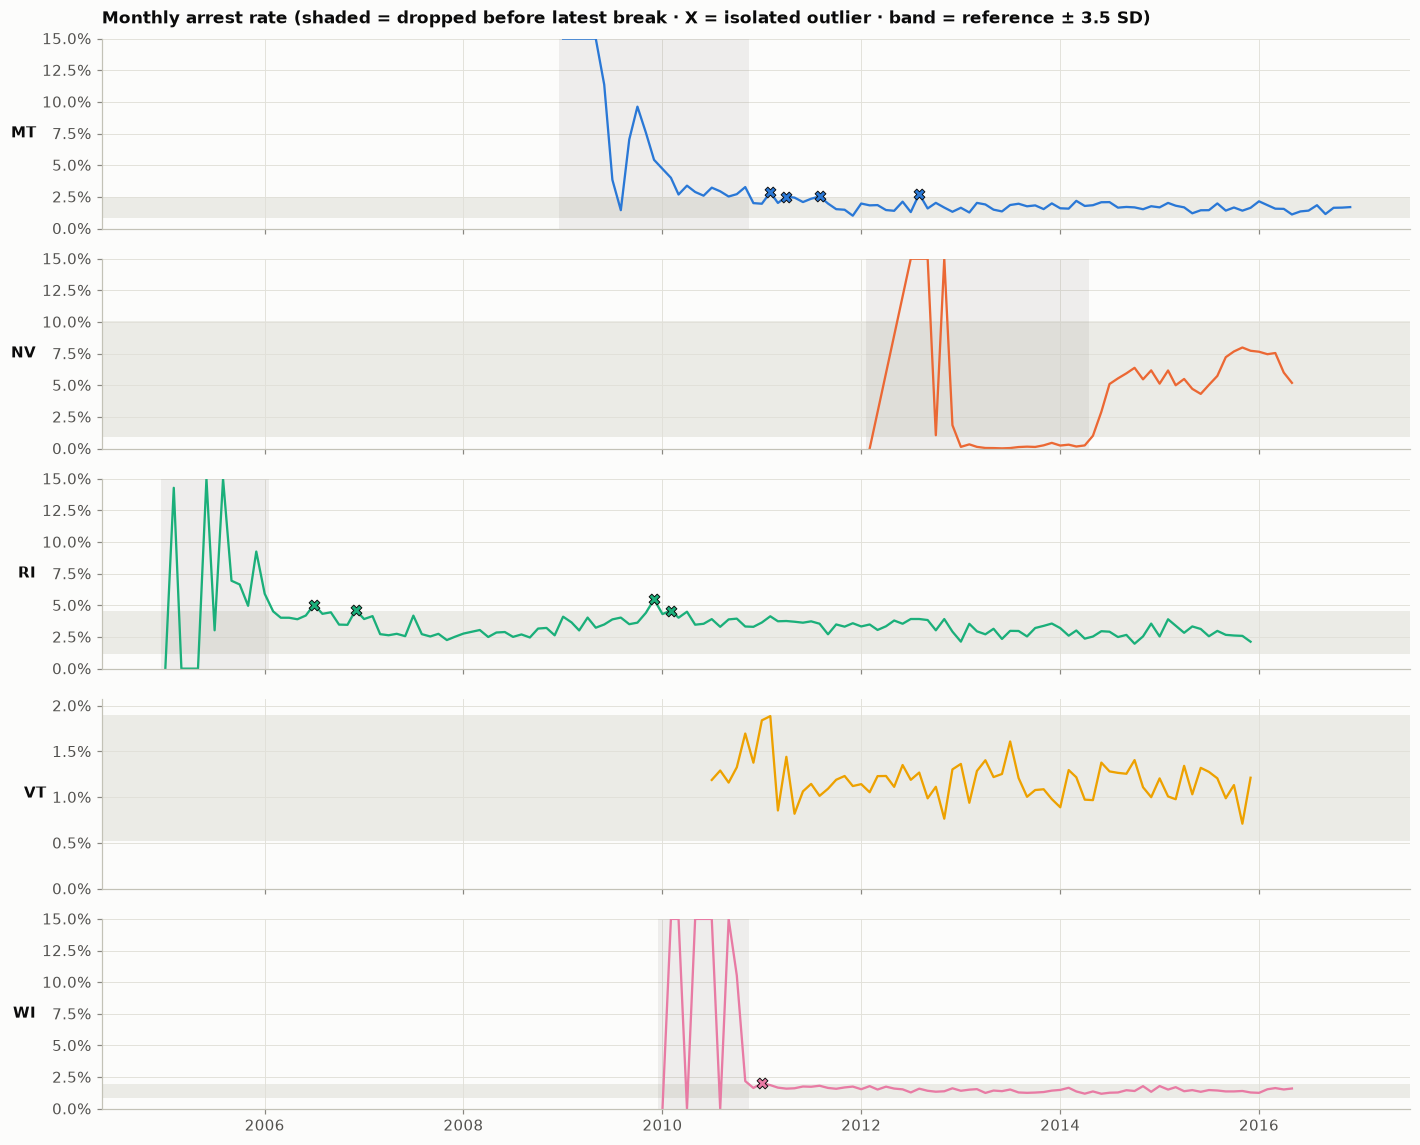

In [29]:
fig, axes = plt.subplots(len(STATES), 1, figsize=(13, 2.1 * len(STATES)), sharex=True)
for ax, s in zip(axes, STATES):
    g = monthly[monthly.state == s]
    t = g.month.dt.to_timestamp()
    med, sd = g.ref_median.iloc[0], g.ref_sd.iloc[0]
    ax.axhspan(med - Z_CUT * sd, med + Z_CUT * sd, color=GRID, alpha=.6, lw=0)
    dropped = g[g.status.eq('before break')]
    if len(dropped):
        ax.axvspan(t.min() - pd.Timedelta(days=15), dropped.month.max().to_timestamp() + pd.Timedelta(days=15),
                   color=MUTED, alpha=.12, lw=0)
    ax.plot(t, g.rate.clip(upper=.15), color=STATE_COLOR[s], lw=1.5)
    sel = g.status.isin(['isolated outlier', 'kept (flagged)'])
    ax.scatter(t[sel], g.rate[sel], marker='X', s=50, color=STATE_COLOR[s], edgecolor=INK, linewidth=.6, zorder=3)
    ax.set_ylim(0, min(.15, g.rate.max() * 1.1)); ax.yaxis.set_major_formatter(PCT)
    ax.set_ylabel(s, rotation=0, ha='right', va='center', fontweight='bold', color=INK)
axes[0].set_title('Monthly arrest rate (shaded = dropped before latest break · X = isolated outlier · band = reference ± 3.5 SD)')
plt.tight_layout(); plt.show()

**Observations**
* **The recent reference windows are tight**: robust SDs are 0.17–0.49 percentage points, except NV (1.31 pp, whose recent window still includes its 2014 ramp). That makes departures easy to see.
* **Structural breaks found (everything up to the break is dropped):**
  * **MT**: dropped through Nov 2010. That covers the 2009 ramp-up months (10–70 stops/month with 11–70% arrest rates, a sign that mainly arrest records were captured) and a 2010 plateau around 3%.
  * **NV**: dropped through Apr 2014, the period with almost no recorded arrests. May 2014 (≈1%) sits just inside the band (z ≈ −3.4) and is kept as a transition month. A stricter cut would start NV in July 2014, as in §1.4.
  * **RI**: dropped through Jan 2006, the 2005 ramp-up with 2–70 stops/month and erratic rates of 0–15%.
  * **WI**: dropped through Nov 2010, a trickle of 1–19 stops/month before the full feed starts in Dec 2010.
  * **VT**: nothing; it never leaves its band.
* **Isolated outliers** (9 months): MT 2011–2012, RI 2006 and 2009–2010, WI Jan 2011. **All 9 are high** (z +3.5 to +5.3), and all fall in the *older* part of the kept window. They reflect the long-run decline in arrest rates as much as one-off anomalies, so dropping them follows the preference for recent data. It also removes high-arrest months selectively, which lowers the base rate slightly. Set `DROP_ISOLATED = False` to keep them.
* After removal, every state's monthly distribution sits inside its reference band, and the spread (box height) shrinks sharply for MT, NV, RI and WI.

## 2.3 Applying the removal

The month-level decisions are joined back onto the stop-level data. `df_model` is the filtered dataset that the
modeling section should use; `df` is left untouched for reference.

In [30]:
period = (df[['state']].assign(month=df.stop_date.dt.to_period('M'))
            .merge(monthly[['state', 'month', 'status', 'keep']], on=['state', 'month'], how='left'))
period.index = df.index
df['period_status'] = period['status'].fillna('no date')
df['period_keep'] = period['keep'].fillna(False).astype(bool)
df_model = df[df.period_keep].copy()

def _summ(d):
    return d.groupby('state').agg(stops=('is_arrested', 'size'), arrests=('is_arrested', 'sum'), rate=('is_arrested', 'mean'))
before, after = _summ(df), _summ(df_model)
impact = pd.concat({'before': before, 'after': after}, axis=1)
impact[('removed', 'stops')] = before.stops - after.stops
impact[('removed', 'share')] = 1 - after.stops / before.stops
impact.loc['ALL'] = [len(df), df.is_arrested.sum(), df.is_arrested.mean(), len(df_model), df_model.is_arrested.sum(),
                     df_model.is_arrested.mean(), len(df) - len(df_model), 1 - len(df_model) / len(df)]
display(impact.style.format({c: '{:,.0f}' for c in impact.columns if c[1] in ('stops', 'arrests')} |
                            {c: '{:.2%}' for c in impact.columns if c[1] in ('rate', 'share')}))

print('Removed stops by reason:')
display(pd.crosstab(df.state, df.period_status, margins=True).style.format('{:,}'))

Removed stops by reason:


period_status,before break,isolated outlier,kept,no date,All
state,,,,,
MT,"135,718","38,308","651,008",11,"825,045"
NV,"284,237",0,"453,029",12,"737,278"
RI,"19,271","15,708","445,629",0,"480,608"
VT,0,0,"281,107",0,"281,107"
WI,935,"17,457","1,040,540",86,"1,059,018"
All,"440,161","71,473","2,871,313",109,"3,383,056"


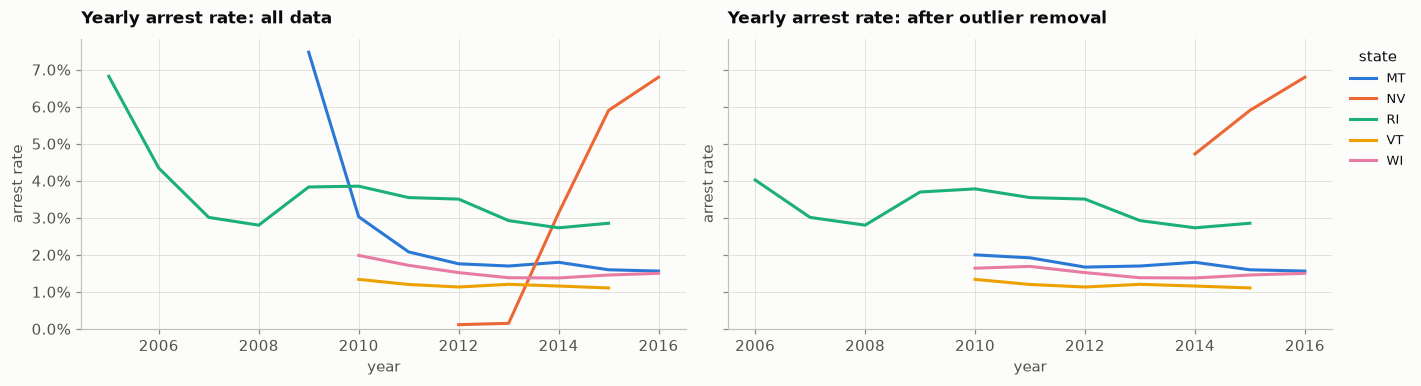

,"max/min yearly rate, all data","max/min yearly rate, after"
state,,
MT,4.77×,1.28×
NV,55.75×,1.44×
RI,2.49×,1.47×
VT,1.21×,1.21×
WI,1.44×,1.23×


In [31]:
yr_after = (df_model.groupby(['state', df_model.stop_date.dt.year.rename('year')])['is_arrested'].mean().unstack('state'))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
rate_lines(yearly['rate'].unstack('state'), axes[0], 'Yearly arrest rate: all data', 'year')
rate_lines(yr_after, axes[1], 'Yearly arrest rate: after outlier removal', 'year')
axes[0].get_legend().remove()
for ax in axes:
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

spread = pd.DataFrame({'max/min yearly rate, all data': yearly['rate'].groupby('state').agg(lambda r: r.max() / r.min()),
                       'max/min yearly rate, after': yr_after.agg(lambda r: r.max() / r.min())})
display(spread.style.format('{:.2f}×'))

**Observations**
* **15.1% of stops are removed** (511,743 of 3.38M), and arrests fall from 79,278 to 70,334:
  * 440k stops sit before a structural break, mainly NV (284k) and MT (136k).
  * 71k fall in isolated outlier months.
  * 109 have no date.
* The state base rates change in different directions:
  * **NV rises from 3.56% to 5.69%**, because its missing-label period is gone.
  * **MT falls from 2.08% to 1.71%** and **RI from 3.45% to 3.27%**, because their inflated ramp-up periods are gone.
  * WI and VT barely change.
  * The pooled rate moves from 2.34% to 2.45%.
* **The between-state gap widens** from 3× to almost 5× (VT 1.18% vs NV 5.69%). This is the more accurate picture, and it reinforces the need for `state` as an explicit model feature and for per-state evaluation.
* The yearly max/min ratio within each state drops from as much as 56× (NV) and 4.8× (MT) to at most 1.5×. The remaining year-to-year movement is a gradual trend, which the model can capture with `year` or by weighting recent years.

**Use `df_model` (2,871,313 stops) for the modeling section.** The `period_status` column on `df` records why each removed stop was dropped.